# Attention-based Neurosymbolic Differentiable Rule Extractor (ANDRE)

**Creator**: Iman Sharifi, G46454668

### Learning the rules for Even/Odd numbers from a generic dataset

In [57]:
import numpy as np
import torch
import torch.nn.functional as F

def interpret_neuron_weights_entropy_(body_preds, pred_values, Weights, entropy_threshold=1.5):
    """
    Interpret the weights of neurons and return a list of 'b_{i}', 'not(b_{i})', or '1'.

    Args:
        body_preds (list): A list of predicate strings for each neuron, like ['b1', 'b2', ...] or ['b1(X1, X2)', 'b2(X3)', ...]
        pred_value: The predicted value to be used in interpretation. it is a scalar value between 0 and 1.
        weights (numpy.ndarray): A 2D numpy array where each row corresponds to the weights of a neuron.

    Returns:
        list: A list of strings ('b_{i}', 'not(b_{i})', or '1') for each neuron.
    """
    
    interpretations = []
    for i, weights in enumerate(Weights):
        weights_tensor = torch.tensor(weights, dtype=torch.float32)
        entropy = -torch.sum(weights_tensor * torch.log(weights_tensor + 1e-10)).item()
        # print(f"Neuron {i+1} weights: {weights}, Entropy: {entropy}")

        if entropy > entropy_threshold:
            interpretations.append('1')
            continue

        # Find predicate value of a given neuron
        pred_value = pred_values[i]
        body_pred = body_preds[i]

        # compute {pred_value*weights[0], (1-pred_value)*weights[1], weights[2]}
        new_weights = [pred_value * weights[0], (1 - pred_value) * weights[1], weights[2]]

        max_index = np.argmax(new_weights)
        if max_index == 0:
            interpretations.append(f'{body_pred}')
            continue
        elif max_index == 1:
            interpretations.append(f'not({body_pred})')
            continue
        else:
            interpretations.append('1')

    return interpretations

def interpret_neuron_weights_entropy(pred_values, Weights, entropy_threshold=0.8):
    """
    Interpret the weights of neurons and return a list of 'b_{i}', 'not(b_{i})', or '1',
    only if entropy is below a threshold to ensure confidence in prediction.

    Args:
        pred_values (numpy.ndarray): A 1D array with predicate values (between 0 and 1).
        Weights (list of list): A 2D list where each row is the softmaxed weights of a neuron.
        entropy_threshold (float): The threshold of entropy above which output is considered uncertain.

    Returns:
        list: A list of strings ('b_{i}', 'not(b_{i})', or '1') for each neuron, or '?' for uncertain.
    """
    interpretations = []
    for i, weights in enumerate(Weights):
        weights_tensor = torch.tensor(weights, dtype=torch.float32)
        entropy = -torch.sum(weights_tensor * torch.log(weights_tensor + 1e-10)).item()
        # print(f"Neuron {i+1} weights: {weights}, Entropy: {entropy}")

        if entropy > entropy_threshold:
            interpretations.append('1')
            continue

        pred_value = pred_values[i]
        new_weights = [pred_value * weights[0], (1 - pred_value) * weights[1], weights[2]]
        max_index = np.argmax(new_weights)

        if max_index == 0:
            interpretations.append(f'b{i+1}')
        elif max_index == 1:
            interpretations.append(f'not(b{i+1})')
        else:
            interpretations.append('1')

    return interpretations

# Network

In [ ]:
import torch
import torch.nn as nn
import torch.optim as optim
from copy import deepcopy
import matplotlib.pyplot as plt
BETA = 20.0  # Example value for beta
# Define CustomNeuron and FuzzyDisjunctionNet
class CustomNeuron(nn.Module):
    def __init__(self):
        super(CustomNeuron, self).__init__()
        self.raw_weights = nn.Parameter(torch.randn(3) * 0.1)  # Small init to prevent saturation

    def forward(self, x):
        self.weights = torch.softmax(self.raw_weights, dim=0)
        x1 = x
        x2 = 1 - x
        x3 = torch.ones_like(x)
        X1 = self.weights[0] * x1
        X2 = self.weights[1] * x2
        X3 = self.weights[2] * x3
        activated_input = X1 + X2 + X3 - (X1 * X2 + X1 * X3 + X2 * X3) + (X1 * X2 * X3)
        return activated_input

class FuzzyDisjunctionNet(nn.Module):
    def __init__(self, num_rules, num_neurons_per_rule, input_dim):
        super(FuzzyDisjunctionNet, self).__init__()
        self.num_rules = num_rules
        self.num_neurons = num_neurons_per_rule
        self.input_dim = input_dim
        self.rules = nn.ModuleList([
            nn.ModuleList([CustomNeuron() for _ in range(num_neurons_per_rule)])
            for _ in range(num_rules)
        ])

    def forward(self, x):
        self.saved_weights = []
        self.entropies = []
        rule_outputs = []

        for rule in self.rules:
            conjunctions = []
            rule_weights = []
            entropy_sum = 0.0
            for i, neuron in enumerate(rule):
                xi = x[:, [i % self.input_dim]]
                conjunctions.append(neuron(xi))
                weights = neuron.weights
                rule_weights.append(weights)
                entropy_sum += -(weights * torch.log(weights + 1e-6)).sum()
            rule_vector = torch.cat(rule_weights)
            self.saved_weights.append(rule_vector)
            self.entropies.append(entropy_sum)
            # Soft min of neuron outputs using attention mechanism
            # find -beta * outputs for all neurons, where beta is a hyperparameter
            attention_weights = torch.softmax(-BETA * torch.stack(conjunctions), dim=0)
            outputs = [attention_weights[i] * conjunctions[i] for i in range(self.num_neurons)]
            # activated_outputs = torch.sigmoid(10*(sum(outputs) - 0.5))  # Apply sigmoid to the sum
            activated_outputs = sum(outputs)
            rule_outputs.append(activated_outputs)

        # Fuzzy disjunction: Soft max of rule outputs using attention mechanism
        # find BETA * rule_outputs for all rules, where beta is a hyperparameter
        attention_weights = torch.softmax(BETA * torch.stack(rule_outputs), dim=0)
        rule_outputs = [attention_weights[i] * rule_outputs[i] for i in range(self.num_rules)]
        # activated_output = torch.sigmoid(10*(sum(rule_outputs) - 0.5))  # Apply sigmoid to the sum
        activated_output = sum(rule_outputs)

        return activated_output

In [4]:
def compute_acc_ratio(model, x, y, rule_idx):
    with torch.no_grad():
        rule = model.rules[rule_idx]
        body_conj = sum(rule[i](x[:, [i]]) for i in range(model.num_neurons_per_rule))
        rule_weights = []
        for neuron in rule:
            weights = torch.softmax(neuron.raw_weights, dim=0).detach().numpy().tolist()
            rule_weights.append(weights)

        num_body_preds = x.shape[1] - sum([1 for w in rule_weights if np.round(w[2]) == 1.0])
        threshold = 0.5**(num_body_preds)
        body = (torch.exp(body_conj) >= threshold).float()

        # Match the shape of body with y
        if body.shape != y.shape:
            body = body.squeeze(-1)

        # find cosine similarity between body and y
        cos_sim = nn.CosineSimilarity(dim=0)(body, y)

        return cos_sim.item()

def compute_acc_ratio_all_rules(model, x, y):
    with torch.no_grad():
        for rule_idx, rule in enumerate(model.rules):
            pred_values = [rule[i](x[:, [i]]) for i in range(model.num_neurons_per_rule)]
            rule_weights = []
            for neuron in rule:
                weights = torch.softmax(neuron.raw_weights, dim=0).detach().numpy().tolist()
                rule_weights.append(weights)

            # This should be double checked because it may not be accurate
            num_body_preds = x.shape[1] - sum([1 for w in rule_weights if np.argmax(w) == 2 and np.round(w[2]) == 1.0]) # x.shape[1] is the number of potential body predicates
            threshold = 0.5**(num_body_preds)
            body = (torch.exp(body_conj) >= threshold).float()

            if rule_idx == 0:
                fuzzy_or = body
            else:
                fuzzy_or = fuzzy_or + body - fuzzy_or * body

        # Match the shape of body with y
        if fuzzy_or.shape != y.shape:
            fuzzy_or = fuzzy_or.squeeze(-1)

        # find cosine similarity between body and y
        cos_sim = nn.CosineSimilarity(dim=0)(fuzzy_or, y)

        return cos_sim.item()

def compute_acc_ratio_all_rules_attention(model, x, y, beta=10.0):
    with torch.no_grad():
        rule_outputs = []
        for rule in model.rules:
            conjunctions = []
            for i, neuron in enumerate(rule):
                xi = x[:, [i % model.input_dim]]
                conjunctions.append(neuron(xi).squeeze())
            # Softmin attention over neurons (optional, or just use sum)
            conjunctions = torch.stack(conjunctions, dim=1)  # (batch, num_neurons)
            attention_weights = torch.softmax(-beta * conjunctions, dim=1)
            outputs = (attention_weights * conjunctions).sum(dim=1)  # (batch,)
            activated_outputs = torch.sigmoid(5 * (outputs - 0.5))
            rule_outputs.append(activated_outputs)

        # Stack rule outputs: shape (num_rules, batch)
        rule_outputs_tensor = torch.stack(rule_outputs, dim=0)  # (num_rules, batch)
        # Softmax attention over rules for each sample (dim=0)
        attention_weights = torch.softmax(beta * rule_outputs_tensor, dim=0)
        # Weighted sum over rules for each sample
        final_output = (attention_weights * rule_outputs_tensor).sum(dim=0)  # (batch,)
        # Compute accuracy
        preds = (final_output > 0.5).float()
        acc = (preds == (y > 0.5)).float().mean().item()
        return acc

# compute_acc_ratio(best_model, X_train, y_train, 0)

## The most stable version of the code:

1 - Added Multiple Initial values

2 - Added entropy for weight exploration 

## Learning More than one rule using NSDRE

## Example rule: 

### $h \leftarrow h_1 \vee h_2$

- $h_1 \leftarrow b_1 \wedge \neg b_2$

- $h_2 \leftarrow b_3 \wedge b_4$

Num Rules: 1, Restart 1/1, Final Loss: 0.4643.
Overall accuracy ratio: 0.6870
Num Rules: 2, Restart 1/1, Final Loss: 0.0621.
Overall accuracy ratio: 0.9490


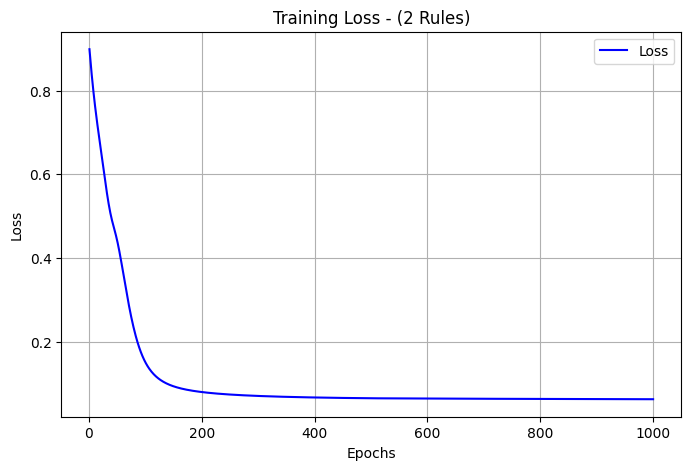


Final SubRules:
Rule 1: h :- b1 and not(b3). -> Accuracy: 0.921 

Rule 2: h :- not(b2) and b4. -> Accuracy: 0.903 


Final Rule:
h :- b1 and not(b3) OR not(b2) and b4.


In [6]:
from collections import Counter
# Parameters
Num_rules = 2
num_neurons_per_rule = 4
input_dim = 4
num_samples = 1000
num_epochs = 1000
num_restarts = 1
similarity_weight = 0.1
entropy_weight = 0.01

# Dataset
torch.manual_seed(42)
X_train = torch.rand(num_samples, input_dim)
y_train = ((((1 - X_train[:, 1]) > 0.5) & (X_train[:, 3] > 0.5))|((X_train[:, 0] > 0.5) & ((1 - X_train[:, 2]) > 0.5))).float()
# y_train = ((X_train[:, 0] > 0.5) & ((1 - X_train[:, 2]) > 0.5)).float()
# y_train = ((X_train[:, 0]) * (1 - X_train[:, 2]) > 0.25).float()

# define y_train = ((X_train[:, 0]) * (1 - X_train[:, 2]) > 0.25).float() using &
# y_train = (((X_train[:, 0] > 0.5) & ((1 - X_train[:, 1]) > 0.5))).float()

# Cosine similarity function
cosine = nn.CosineSimilarity(dim=1)

# Multi-Restart Training
best_state_dict = None
best_loss = float('inf')
best_acc_ratio = 0
best_losses = []

for num_rules in range(Num_rules):

    for restart in range(num_restarts):
        model_nsre = FuzzyDisjunctionNet(num_rules + 1, num_neurons_per_rule, input_dim)
        # criterion = nn.BCEWithLogitsLoss()
        criterion = nn.BCELoss()  # Use BCELoss for sigmoid outputs
        optimizer = optim.AdamW(model_nsre.parameters(), lr=0.01, weight_decay=1e-4)
        scheduler = optim.lr_scheduler.StepLR(optimizer, step_size=500, gamma=0.5)

        losses_nsre = []

        for epoch in range(num_epochs):
            optimizer.zero_grad()
            outputs = model_nsre(X_train).squeeze()
            bce_loss = criterion(outputs, y_train)

            # Cosine similarity loss
            penalty = 0.0
            for i in range(num_rules):
                for j in range(i + 1, num_rules):
                    wi = model_nsre.saved_weights[i].view(num_neurons_per_rule, -1)
                    wj = model_nsre.saved_weights[j].view(num_neurons_per_rule, -1)
                    pairwise_sim = cosine(wi, wj).mean()
                    penalty += pairwise_sim

            # Entropy regularization for exploration
            entropy_term = sum(model_nsre.entropies)

            # total_loss = bce_loss + similarity_weight * penalty - entropy_weight * entropy_term #+ 0.1*sum_weights_loss
            # total_loss = bce_loss - entropy_weight * entropy_term + 0.1 * sum_weights_loss
            total_loss = bce_loss - entropy_weight * entropy_term
            total_loss.backward()
            nn.utils.clip_grad_norm_(model_nsre.parameters(), max_norm=1.0)
            optimizer.step()
            scheduler.step()
            losses_nsre.append(total_loss.item())

        final_loss = losses_nsre[-1]
        print(f"Num Rules: {num_rules + 1}, Restart {restart+1}/{num_restarts}, Final Loss: {final_loss:.4f}.")
        if final_loss < best_loss:
            best_loss = final_loss
            # best_state_dict = deepcopy(model_nsre.state_dict())
            best_losses = losses_nsre
            # best_num_rules = num_rules + 1  # Store the best number of rules
            # print(f"New best model found with {best_num_rules} rules and loss: {best_loss:.4f}")

        # Compute acc_ratio on training data
        # for r in range(len(model_nsre.rules)):
        #     acc_ratio = compute_acc_ratio(model_nsre, X_train, y_train, r)
        #     print(f"Rule {r + 1} accuracy ratio: {acc_ratio:.4f}")
        acc_ratio_all = compute_acc_ratio_all_rules_attention(model_nsre, X_train, y_train)
        if acc_ratio_all > best_acc_ratio:
            best_acc_ratio = acc_ratio_all
            best_state_dict = deepcopy(model_nsre.state_dict())
            best_num_rules = num_rules + 1

        print(f"Overall accuracy ratio: {acc_ratio_all:.4f}")
# Load the best model
best_model = FuzzyDisjunctionNet(best_num_rules, num_neurons_per_rule, input_dim)
best_model.load_state_dict(best_state_dict)

# Plot loss curve
plt.figure(figsize=(8, 5))
plt.plot(range(1, num_epochs + 1), best_losses, label="Loss", color="blue")
plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.title(f"Training Loss - ({best_num_rules} Rules)")
plt.legend()
plt.grid(True)
plt.show()

# Save final weights for inspection
Weights_nsre = []
for rule in best_model.rules:
    rule_weights = []
    for neuron in rule:
        weights = torch.softmax(neuron.raw_weights, dim=0).detach().numpy().tolist()
        # weights = torch.sigmoid(neuron.raw_weights).detach().numpy().tolist()
        rule_weights.append(weights)
    Weights_nsre.append(rule_weights)
# print("\nFinal Weights of the Network:")
# for i, weights in enumerate(Weights_nsre):
#     print(f"Rule {i+1}: {weights}")

# Rule interpretation
Predicate_values = X_train

Final_rules = []
for rule_num, weights in enumerate(Weights_nsre):
    Extracted_rules = []
    for i in range(len(Predicate_values)):
        pred_values = Predicate_values[i].numpy()
        preds = interpret_neuron_weights_entropy(pred_values, weights)
        refined_preds = [pred for pred in preds if pred != '1']
        rule = f"h :- " + " and ".join(refined_preds) + "."
        Extracted_rules.append(rule)

    rule_counts = Counter(Extracted_rules)
    most_common_rule, count = rule_counts.most_common(1)[0]
    rule_accuracy = float(count/len(Extracted_rules))
    # print(f"The most repeated rule is: '{most_common_rule}'")
    # print(f"Accuracy over training data: {rule_accuracy}.")
    # Save the most common rule with its accuracy
    Final_rules.append((most_common_rule, rule_accuracy))

# Sort rules by accuracy
Final_rules.sort(key=lambda x: x[1], reverse=True)
# Extract the rules from the sorted list
Final_rules_ = [rule[0] for rule in Final_rules]
# Print the final rules with their accuracies
print("\n======================================")
print("Final SubRules:")
for i, rule in enumerate(Final_rules):
    print(f"Rule {i+1}: {rule[0]} -> Accuracy: {rule[1]} \n")

# remove the "h :- " part from each rule
Final_rules = [rule.replace(f"h :- ", "") for rule_num, rule in enumerate(Final_rules_)]

# remove the "."
Final_rules = [rule.replace(".", "") for rule in Final_rules]

# convert the rules to a single rule
final_rule = "h :- " + " OR ".join(Final_rules) + "."
print("\n======================================")
print("Final Rule:")
print(final_rule)
print("======================================")


## Network

In [6]:
import torch
import torch.nn as nn
import torch.optim as optim
from copy import deepcopy
import matplotlib.pyplot as plt
BETA = 20.0  # Example value for beta
LAMBDA = 10.0  # Example value for lambda

# Define CustomNeuron and FuzzyDisjunctionNet
class CustomNeuron(nn.Module):
    def __init__(self):
        super(CustomNeuron, self).__init__()
        self.raw_weights = nn.Parameter(torch.randn(3) * 0.1)  # Small init to prevent saturation

    def forward(self, x):
        self.weights = torch.softmax(self.raw_weights, dim=0)
        x1 = x
        x2 = 1 - x
        x3 = torch.ones_like(x)
        X1 = self.weights[0] * x1
        X2 = self.weights[1] * x2
        X3 = self.weights[2] * x3
        activated_input = X1 + X2 + X3 - (X1 * X2 + X1 * X3 + X2 * X3) + (X1 * X2 * X3)
        return activated_input

# Define FuzzyDisjunctionNet
class FuzzyDisjunctionNet(nn.Module):
    def __init__(self, num_rules, num_neurons_per_rule, input_dim, variable_matrix):
        super(FuzzyDisjunctionNet, self).__init__()
        self.num_rules = num_rules
        self.num_neurons = num_neurons_per_rule
        self.input_dim = input_dim
        self.V = variable_matrix
        self.rules = nn.ModuleList([
            nn.ModuleList([CustomNeuron() for _ in range(num_neurons_per_rule)])
            for _ in range(num_rules)
        ])

    def forward(self, x):
        self.saved_weights = []
        self.entropies = []
        self.M_matrices = []
        rule_outputs = []

        for i, rule in enumerate(self.rules):
            conjunctions = []
            rule_weights = []
            entropy_sum = 0.0
            P = []
            for j, neuron in enumerate(rule):
                xi = x[:, [j % self.input_dim]]
                conjunctions.append(neuron(xi))
                weights = neuron.weights
                rule_weights.append(weights)
                entropy_sum += -(weights * torch.log(weights + 1e-6)).sum()
                P.append(1.0 - weights[2])  # 1 - w3

            rule_vector = torch.cat(rule_weights)
            self.saved_weights.append(rule_vector)
            self.entropies.append(entropy_sum)

            P_tensor = torch.stack(P)
            M = torch.matmul(P_tensor, self.V)
            self.M_matrices.append(M)

            # Soft min of neuron outputs using attention mechanism
            # find -beta * outputs for all neurons, where beta is a hyperparameter
            attention_weights = torch.softmax(-BETA * torch.stack(conjunctions), dim=0)
            outputs = [attention_weights[i] * conjunctions[i] for i in range(self.num_neurons)]
            activated_outputs = torch.sigmoid(LAMBDA*(sum(outputs) - 0.5))  # Apply sigmoid to the sum
            rule_outputs.append(activated_outputs)

        # Fuzzy disjunction: Soft max of rule outputs using attention mechanism
        # find BETA * rule_outputs for all rules, where beta is a hyperparameter
        attention_weights = torch.softmax(BETA * torch.stack(rule_outputs), dim=0)
        rule_outputs = [attention_weights[i] * rule_outputs[i] for i in range(self.num_rules)]
        activated_output = torch.sigmoid(LAMBDA*(sum(rule_outputs) - 0.5))  # Apply sigmoid to the sum

        return activated_output

### PPO Taxi-v3

Step: 0, Avg Reward: 0.00, steps:99.
Step: 1, Avg Reward: -22.92, steps:25.
Step: 2, Avg Reward: -5.79, steps:99.
Step: 3, Avg Reward: -7.57, steps:99.
Step: 4, Avg Reward: -7.57, steps:99.
Step: 5, Avg Reward: -6.84, steps:99.
Step: 6, Avg Reward: -6.84, steps:99.
Step: 7, Avg Reward: -6.11, steps:99.
Step: 8, Avg Reward: -6.11, steps:99.
Step: 9, Avg Reward: -7.99, steps:72.
Step: 10, Avg Reward: -5.81, steps:99.
Step: 11, Avg Reward: -5.66, steps:99.
Step: 12, Avg Reward: -5.66, steps:99.
Step: 13, Avg Reward: -6.66, steps:99.
Step: 14, Avg Reward: -6.66, steps:99.
Step: 15, Avg Reward: -5.47, steps:99.
Step: 16, Avg Reward: -5.47, steps:99.
Step: 17, Avg Reward: -6.02, steps:99.
Step: 18, Avg Reward: -6.02, steps:99.
Step: 19, Avg Reward: -5.66, steps:99.
Step: 20, Avg Reward: -5.66, steps:99.
Step: 21, Avg Reward: -4.66, steps:99.
Step: 22, Avg Reward: -4.66, steps:99.
Step: 23, Avg Reward: -4.84, steps:99.
Step: 24, Avg Reward: -4.84, steps:99.
Step: 25, Avg Reward: -4.66, steps:

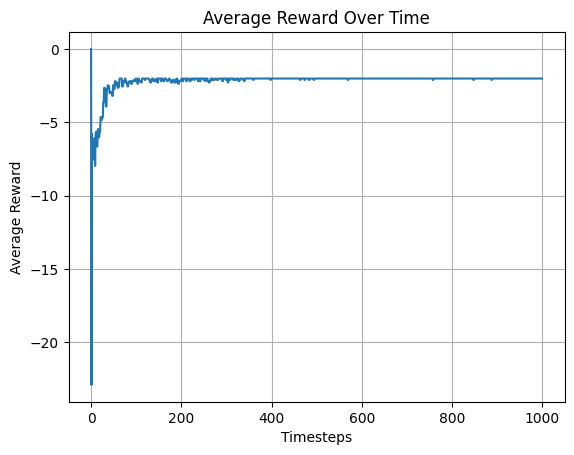

In [4]:
# Re-executing the corrected PPO loop after kernel reset

import gym
import torch
import torch.nn as nn
import torch.optim as optim
import numpy as np
import matplotlib.pyplot as plt

# Patch for numpy.bool8 deprecation
if not hasattr(np, "bool8"):
    np.bool8 = np.bool_

# === Hyperparameters ===
env_name = "Taxi-v3"
learning_rate = 1e-3
gamma = 0.99
clip_eps = 0.2
update_epochs = 4
batch_size = 32
total_timesteps = 1000
timesteps_per_batch = 100

env = gym.make(env_name)
obs_space = env.observation_space.n
act_space = env.action_space.n

# === Policy Network (Actor-Critic) ===
class PPOPolicy(nn.Module):
    def __init__(self, obs_dim, act_dim):
        super().__init__()
        self.embed = nn.Embedding(obs_dim, 64)
        self.actor = nn.Sequential(nn.Linear(64, 64), nn.ReLU(), nn.Linear(64, act_dim))
        self.critic = nn.Sequential(nn.Linear(64, 64), nn.ReLU(), nn.Linear(64, 1))

    def forward(self, x):
        x = self.embed(x)
        logits = self.actor(x)
        value = self.critic(x)
        return logits, value.squeeze()

    def act(self, x):
        logits, value = self.forward(x)
        dist = torch.distributions.Categorical(logits=logits)
        action = dist.sample()
        # action = torch.argmax(torch.softmax(logits, dim=-1), dim=-1)  # Use argmax for deterministic action
        return action, dist.log_prob(action), dist.entropy(), value

# === GAE Computation ===
def compute_gae(rewards, values, dones, gamma=0.99, lam=0.95):
    advantages, gae = [], 0
    values = values + [0]
    for t in reversed(range(len(rewards))):
        delta = rewards[t] + gamma * values[t+1] * (1 - dones[t]) - values[t]
        gae = delta + gamma * lam * (1 - dones[t]) * gae
        advantages.insert(0, gae)
    returns = [adv + v for adv, v in zip(advantages, values[:-1])]
    return advantages, returns

# === Initialize PPO ===
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model = PPOPolicy(obs_space, act_space).to(device)
optimizer = optim.Adam(model.parameters(), lr=learning_rate)

obs = env.reset()
if isinstance(obs, tuple): obs = obs[0]
episode_rewards = []
ep_reward = 0
all_avg_rewards = []

for t in range(total_timesteps):
    batch_obs, batch_acts, batch_log_probs, batch_vals, batch_dones, batch_rewards = [], [], [], [], [], []
    for step_cnt in range(timesteps_per_batch):
        obs_tensor = torch.tensor([obs], dtype=torch.long).to(device)
        with torch.no_grad():
            action, log_prob, _, value = model.act(obs_tensor)
        next_obs, reward, terminated, truncated, _ = env.step(action.item())
        done = terminated or truncated

        next_obs_int = next_obs[0] if isinstance(next_obs, tuple) else next_obs

        batch_obs.append(obs)
        batch_acts.append(action.item())
        
        batch_log_probs.append(log_prob.item())
        batch_vals.append(value.item())
        batch_rewards.append(reward)
        batch_dones.append(done)
        ep_reward += reward

        obs = next_obs_int
        if done:
            obs = env.reset()
            if isinstance(obs, tuple): obs = obs[0]
            episode_rewards.append(ep_reward)
            ep_reward = 0
            break  # break the inner loop when done

    # GAE and Returns
    with torch.no_grad():
        last_val = model(torch.tensor([obs], dtype=torch.long).to(device))[1].item()
    batch_vals.append(last_val)
    advantages, returns = compute_gae(batch_rewards, batch_vals[:-1], batch_dones, gamma)

    # Convert to tensors
    obs_tensor = torch.tensor(batch_obs, dtype=torch.long).to(device)
    act_tensor = torch.tensor(batch_acts, dtype=torch.long).to(device)
    old_log_probs = torch.tensor(batch_log_probs, dtype=torch.float32).to(device)
    adv_tensor = torch.tensor(advantages, dtype=torch.float32).to(device)
    ret_tensor = torch.tensor(returns, dtype=torch.float32).to(device)

    # Normalize advantages
    adv_tensor = (adv_tensor - adv_tensor.mean()) / (adv_tensor.std() + 1e-8)

    # PPO Updates
    for _ in range(update_epochs):
        logits, values = model(obs_tensor)
        dist = torch.distributions.Categorical(logits=logits)
        log_probs = dist.log_prob(act_tensor)
        ratios = torch.exp(log_probs - old_log_probs)

        surr1 = ratios * adv_tensor
        surr2 = torch.clamp(ratios, 1 - clip_eps, 1 + clip_eps) * adv_tensor
        policy_loss = -torch.min(surr1, surr2).mean()
        value_loss = nn.functional.mse_loss(values, ret_tensor)
        entropy_loss = dist.entropy().mean()
        loss = policy_loss + 0.5 * value_loss - 0.001 * entropy_loss

        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

    avg_reward = episode_rewards[-1] / step_cnt if episode_rewards else 0
    all_avg_rewards.append(avg_reward)
    print(f"Step: {t}, Avg Reward: {avg_reward:.2f}, steps:{step_cnt}.")

# Plot average rewards
plt.plot(all_avg_rewards)
plt.xlabel("Timesteps")
plt.ylabel("Average Reward")
plt.title("Average Reward Over Time")
plt.grid()
plt.show()


In [27]:
import gym

# Fixed location coordinates for R, G, Y, B
LOCATION_COORDS = {
    0: (0, 0),  # R
    1: (0, 4),  # G
    2: (4, 0),  # Y
    3: (4, 3)   # B
}

# Decode Taxi-v3 state
def decode_taxi_state(state):
    destination = state % 4
    state //= 4
    passenger_location = state % 5
    state //= 5
    taxi_col = state % 5
    taxi_row = state // 5
    return taxi_row, taxi_col, passenger_location, destination

# Manhattan distance
def manhattan_distance(r1, c1, r2, c2):
    return abs(r1 - r2) + abs(c1 - c2)

# Check valid move (walls are encoded in Taxi-v3 dynamics)
def is_valid_move(taxi_row, taxi_col, action):
    if action == 0 and taxi_row < 4: return True   # South
    if action == 1 and taxi_row > 0: return True   # North
    if action == 2 and taxi_col < 4: return True   # East
    if action == 3 and taxi_col > 0: return True   # West
    return False

# Compute new position if action is taken
def move(taxi_row, taxi_col, action):
    if action == 0 and taxi_row < 4: return taxi_row + 1, taxi_col
    if action == 1 and taxi_row > 0: return taxi_row - 1, taxi_col
    if action == 2 and taxi_col < 4: return taxi_row, taxi_col + 1
    if action == 3 and taxi_col > 0: return taxi_row, taxi_col - 1
    return taxi_row, taxi_col  # Invalid move (hit wall)

# Find best movement actions in a state
def best_movement_actions(state):
    taxi_row, taxi_col, pass_loc, dest = decode_taxi_state(state)

    # Target to move toward (passenger or destination)
    if pass_loc < 4:
        target_row, target_col = LOCATION_COORDS[pass_loc]
    else:
        target_row, target_col = LOCATION_COORDS[dest]

    current_dist = manhattan_distance(taxi_row, taxi_col, target_row, target_col)

    best_actions = []
    min_dist = current_dist

    for action in [0, 1, 2, 3]:  # S, N, E, W
        if not is_valid_move(taxi_row, taxi_col, action):
            continue
        new_r, new_c = move(taxi_row, taxi_col, action)
        new_dist = manhattan_distance(new_r, new_c, target_row, target_col)
        if new_dist < min_dist:
            best_actions = [action]
            min_dist = new_dist
        elif new_dist == min_dist:
            best_actions.append(action)

    return best_actions

def binary_distance_flags(state):
    """
    Returns a binary vector of shape (6,) where:
    - Elements 0–3 correspond to movement actions (South, North, East, West)
    - Elements 4–5 are Pickup and Dropoff, defaulted to 0
    Closer actions to the current target get 1
    """
    flags = [0] * 6
    taxi_row, taxi_col, pass_loc, dest = decode_taxi_state(state)

    # Define target location
    if pass_loc < 4:
        target_row, target_col = LOCATION_COORDS[pass_loc]
    else:
        target_row, target_col = LOCATION_COORDS[dest]

    current_dist = manhattan_distance(taxi_row, taxi_col, target_row, target_col)

    min_dist = current_dist
    action_distances = []

    for action in range(4):  # Only move actions
        if is_valid_move(taxi_row, taxi_col, action):
            new_row, new_col = move(taxi_row, taxi_col, action)
            new_dist = manhattan_distance(new_row, new_col, target_row, target_col)
        else:
            new_dist = float('inf')  # Invalid move

        action_distances.append(new_dist)
        min_dist = min(min_dist, new_dist)

    # Assign binary flags
    for action in range(4):
        if action_distances[action] == min_dist:
            flags[action] = 1

    # check if the taxi is at the passenger's location
    if pass_loc < 4:
        if taxi_row == LOCATION_COORDS[pass_loc][0] and taxi_col == LOCATION_COORDS[pass_loc][1]:
            flags[4] = 1  # Pickup

    # check if the taxi is at the destination
    if dest < 4:
        if taxi_row == LOCATION_COORDS[dest][0] and taxi_col == LOCATION_COORDS[dest][1]:
            flags[5] = 1  # Dropoff

    return flags

def passenger_status(state):
    """
    Returns a binary vector of shape (1,) indicating if the passenger is in the taxi.
    1 if passenger is in the taxi, 0 otherwise.
    """
    _, _, pass_loc, _ = decode_taxi_state(state)
    return int(pass_loc == 4)

def extract_high_level_features(state):
    """
    Extracts high-level symbolic features from the Taxi-v3 state.
    Returns a binary vector of shape (6,) with movement actions and pickup/dropoff flags.
    """
    taxi_row, taxi_col, pass_loc, _ = decode_taxi_state(state)
    state_ = [taxi_row / 4, taxi_col / 4]  # Taxi position normalized
    flags = binary_distance_flags(state)
    # Pickup and Dropoff actions are not considered in this example, so they remain 0

    # Valid moves based on Taxi-v3 dynamics
    valid_moves = [is_valid_move(taxi_row, taxi_col, action) for action in range(4)]

    # Passenger status
    pass_status = [passenger_status(state)]
    states = valid_moves + flags + pass_status
    return torch.tensor(states, dtype=torch.float32).unsqueeze(0)  # Shape (1, 6)

def extract_desired_rule_outputs(state, reward):
    """
    Extracts desired rule outputs based on the current state and reward.
    Returns a binary vector of shape (6,) with movement actions and pickup/dropoff flags.
    """
    flags = binary_distance_flags(state)
    outputs = flags
    pass_status = passenger_status(state)
    # If the reward is positive, we assume the action was successful
    if flags[5] == 1:
        if pass_status == 1:
            outputs = [0, 0, 0, 0, 0, 1]
        else:
            outputs[5] = 0  # Invalid Dropoff
    elif flags[4] == 1:
        if pass_status == 0:
            outputs = [0, 0, 0, 0, 1, 0]
        else:
            outputs[4] = 0

    return torch.tensor(outputs, dtype=torch.float32).unsqueeze(0)  # Shape (1, 6)


In [6]:
import torch
import torch.nn as nn
import torch.optim as optim
import gym
import matplotlib.pyplot as plt

# === Hyperparameters ===
BETA = 10.0
NUM_ACTIONS = 6
INPUT_DIM = 11
GAMMA = 0.99
LAMBDA = 0.95
NUM_EPISODES = 1000
LR = 0.001
STEPS_PER_BATCH = 100
UPDATE_EPOCHS = 4
MINIBATCH_SIZE = 32

# Patch for numpy.bool8 deprecation
if not hasattr(np, "bool8"):
    np.bool8 = np.bool_

# === Dummy high-level feature extractor (replace with your real one) ===
# def extract_high_level_features(state):
#     return torch.rand(1, INPUT_DIM)

# === CustomNeuron ===
class CustomNeuron(nn.Module):
    def __init__(self):
        super().__init__()
        self.raw_weights = nn.Parameter(torch.randn(3) * 0.1)

    def forward(self, x):
        weights = torch.softmax(self.raw_weights, dim=0)
        x1, x2, x3 = x, 1 - x, torch.ones_like(x)
        X1, X2, X3 = weights[0]*x1, weights[1]*x2, weights[2]*x3
        return X1 + X2 + X3 - (X1*X2 + X1*X3 + X2*X3) + (X1*X2*X3)

# === ANDRE ===
class ANDRE(nn.Module):
    def __init__(self, num_rules, input_dim):
        super().__init__()
        self.rules = nn.ModuleList([
            nn.ModuleList([CustomNeuron() for _ in range(input_dim)])
            for _ in range(num_rules)
        ])
        self.input_dim = input_dim

    def forward(self, x):
        batch_size = x.shape[0]
        rule_outputs = []
        for rule in self.rules:
            conj = [neuron(x[:, i % self.input_dim].unsqueeze(1)) for i, neuron in enumerate(rule)]
            conj = torch.stack(conj)
            attn = torch.softmax(-BETA * conj.squeeze(-1), dim=0)
            rule_out = torch.sigmoid(5 * (torch.sum(attn * conj.squeeze(-1), dim=0) - 0.5))
            rule_outputs.append(rule_out)
        rule_outputs = torch.stack(rule_outputs)
        rule_attn = torch.softmax(BETA * rule_outputs, dim=0)
        return torch.sigmoid(5 * (torch.sum(rule_attn * rule_outputs, dim=0) - 0.5))

# === Value Network ===
class ValueNetwork(nn.Module):
    def __init__(self, state_dim=INPUT_DIM):
        super().__init__()
        self.fc = nn.Sequential(
            nn.Linear(state_dim, 64),
            nn.ReLU(),
            nn.Linear(64, 1)
        )

    def forward(self, state):
        return self.fc(state).squeeze(-1)

# === GAE ===
def compute_gae(rewards, values, dones, gamma=0.99, lam=0.95):
    advantages, gae = [], 0
    values = values + [0]
    for t in reversed(range(len(rewards))):
        delta = rewards[t] + gamma * values[t+1] * (1 - dones[t]) - values[t]
        gae = delta + gamma * lam * (1 - dones[t]) * gae
        advantages.insert(0, gae)
    returns = [adv + v for adv, v in zip(advantages, values[:-1])]
    return advantages, returns

# === Init ===
env = gym.make("Taxi-v3")
andre_nets = nn.ModuleList([ANDRE(1, INPUT_DIM) for _ in range(NUM_ACTIONS)])
value_net = ValueNetwork(state_dim=INPUT_DIM)
optimizer = optim.Adam([p for net in andre_nets for p in net.parameters()] + list(value_net.parameters()), lr=LR)

# === Training ===
reward_log = []
avg_reward_log = []
obs = env.reset()
if isinstance(obs, tuple): obs = obs[0]

for ep in range(NUM_EPISODES):
    batch_obs, batch_acts, batch_log_probs, batch_vals, batch_rewards, batch_dones, batch_entropies = [], [], [], [], [], [], []
    ep_reward, step_count = 0, 0

    while step_count < STEPS_PER_BATCH:
        state = obs
        x = extract_high_level_features(state)
        logits = torch.cat([andre(x) for andre in andre_nets], dim=0)
        logits = 10 * (logits - logits.mean(dim=0, keepdim=True))
        dist = torch.distributions.Categorical(logits=logits)
        action = dist.sample()

        log_prob = dist.log_prob(action)
        entropy = dist.entropy()
        value = value_net(x)

        next_obs, reward, terminated, truncated, _ = env.step(action.item())
        done = terminated or truncated

        batch_obs.append(state)
        batch_acts.append(action.item())
        batch_log_probs.append(log_prob.item())
        batch_vals.append(value.item())
        batch_rewards.append(reward)
        batch_dones.append(done)
        batch_entropies.append(entropy.item())

        obs = next_obs if not isinstance(next_obs, tuple) else next_obs[0]
        ep_reward += reward
        step_count += 1

        if done or step_count >= STEPS_PER_BATCH:
            reward_log.append(ep_reward)
            obs = env.reset()
            if isinstance(obs, tuple): obs = obs[0]
            ep_reward = 0
            break

    with torch.no_grad():
        last_val = value_net(extract_high_level_features(obs)).item()

    values = batch_vals + [last_val]
    advantages, returns = compute_gae(batch_rewards, values, batch_dones, GAMMA, LAMBDA)
    advantages = torch.tensor(advantages)
    returns = torch.tensor(returns)
    advantages = (advantages - advantages.mean()) / (advantages.std() + 1e-8)

    actual_batch_size = len(batch_obs)
    if actual_batch_size == 0:
        continue

    obs_tensor = torch.tensor(batch_obs, dtype=torch.long)
    act_tensor = torch.tensor(batch_acts, dtype=torch.long)
    logp_old = torch.tensor(batch_log_probs)
    entropies = torch.tensor(batch_entropies)

    for _ in range(UPDATE_EPOCHS):
        for i in range(0, actual_batch_size, MINIBATCH_SIZE):
            idx = slice(i, i + MINIBATCH_SIZE)
            obs_list = obs_tensor[idx].tolist()
            x_batch = torch.cat([extract_high_level_features(s) for s in obs_list])
            logits = torch.stack([andre(x_batch) for andre in andre_nets], dim=1).squeeze(0)
            logits = 10 * (logits - logits.mean(dim=1, keepdim=True))
            dist = torch.distributions.Categorical(logits=logits)
            logp = dist.log_prob(act_tensor[idx])
            ratio = torch.exp(logp - logp_old[idx])

            surr1 = ratio * advantages[idx]
            surr2 = torch.clamp(ratio, 0.8, 1.2) * advantages[idx]
            policy_loss = -torch.min(surr1, surr2).mean()

            val_pred = value_net(x_batch)
            value_loss = nn.functional.mse_loss(val_pred, returns[idx])
            entropy_bonus = entropies[idx].mean()
            loss = policy_loss + 0.5 * value_loss - 0.001 * entropy_bonus

            optimizer.zero_grad()
            loss.backward()
            nn.utils.clip_grad_norm_([p for net in andre_nets for p in net.parameters()], 1.0)
            optimizer.step()
    avg_reward = reward_log[-1] / step_count if step_count > 0 else 0
    avg_reward_log.append(avg_reward)
    print(f"Episode {ep+1}/{NUM_EPISODES}, Avg Reward: {avg_reward:.2f}, Total Steps: {step_count}")

# Plotting
plt.plot(avg_reward_log)
plt.title("PPO ANDRE-Critic Training on Taxi-v3")
plt.xlabel("Episode")
plt.ylabel("Average Reward")
plt.grid(True)
plt.show()


Episode 1/1000, Avg Reward: -3.52, Total Steps: 100
Episode 2/1000, Avg Reward: -4.15, Total Steps: 100
Episode 3/1000, Avg Reward: -3.97, Total Steps: 100
Episode 4/1000, Avg Reward: -3.97, Total Steps: 100
Episode 5/1000, Avg Reward: -3.97, Total Steps: 100
Episode 6/1000, Avg Reward: -4.42, Total Steps: 100
Episode 7/1000, Avg Reward: -3.70, Total Steps: 100
Episode 8/1000, Avg Reward: -4.60, Total Steps: 100
Episode 9/1000, Avg Reward: -2.98, Total Steps: 100
Episode 10/1000, Avg Reward: -3.52, Total Steps: 100
Episode 11/1000, Avg Reward: -2.71, Total Steps: 100
Episode 12/1000, Avg Reward: -4.69, Total Steps: 100
Episode 13/1000, Avg Reward: -3.52, Total Steps: 100
Episode 14/1000, Avg Reward: -3.16, Total Steps: 100
Episode 15/1000, Avg Reward: -3.52, Total Steps: 100
Episode 16/1000, Avg Reward: -2.80, Total Steps: 100
Episode 17/1000, Avg Reward: -4.06, Total Steps: 100
Episode 18/1000, Avg Reward: -3.52, Total Steps: 100
Episode 19/1000, Avg Reward: -3.43, Total Steps: 100
Ep

KeyboardInterrupt: 

In [7]:
andre_weights = []
for action_idx, andre_net in enumerate(andre_nets):
    rule_weights = []
    for rule in andre_net.rules:
        neuron_weights = []
        for neuron in rule:
            weights = torch.softmax(neuron.raw_weights, dim=0).detach().numpy().tolist()
            eta = 10
            weights = [float(weight + eta * (weight - np.mean(weights))) for weight in weights]  # Apply eta to weights
            weights = [max(0, min(1, weight)) for weight in weights]
            neuron_weights.append(weights)
        rule_weights.append(neuron_weights)
    andre_weights.append(rule_weights)
andre_weights

[[[[0, 0, 1],
   [1, 0, 0],
   [0, 0, 1],
   [0, 0, 1],
   [0, 0, 1],
   [0, 0, 1],
   [0, 0.7941130995750427, 1],
   [0, 0, 1],
   [0, 0.6589202682177228, 1],
   [0, 1, 0],
   [0, 0, 1]]],
 [[[1, 0, 0],
   [0, 1, 0],
   [0, 1, 0],
   [0.1573003033796948, 0.07861135403315245, 0.7640883425871533],
   [0.9674561023712158, 0.04238519072532654, 0],
   [0.4579358994960785, 0.7746386528015137, 0],
   [1, 0, 0],
   [0, 1, 0.11524434884389223],
   [0.6291660368442535, 0.2797617018222809, 0.0910722017288208],
   [1, 0, 0.12054301301638304],
   [0.567574103673299, 0.36782573660214724, 0.06460021932919802]]],
 [[[0, 0, 1],
   [0.07590600848197937, 0, 1],
   [0, 0, 1],
   [1, 0, 0],
   [0, 0, 1],
   [0, 0, 1],
   [0, 0, 1],
   [0, 0, 1],
   [0, 0, 1],
   [0, 0.10520862539609255, 1],
   [0, 0, 1]]],
 [[[1, 0, 0],
   [0, 1, 0],
   [1, 0, 0],
   [0, 1, 0],
   [1, 0, 0],
   [0, 1, 0],
   [1, 0, 0.01677031318346678],
   [0, 1, 0.04940875371297182],
   [1, 0, 0],
   [0.9723975459734601, 0, 0.33909071485

## Adding Binary Loss Function

In [69]:
import torch
import torch.nn as nn
import torch.optim as optim
import gym
import matplotlib.pyplot as plt

# === Hyperparameters ===
BETA = 20.0
NUM_ACTIONS = 6
INPUT_DIM = 11
GAMMA = 0.99
LAMBDA = 0.95
NUM_EPISODES = 1000
LR = 0.01
STEPS_PER_BATCH = 1024
UPDATE_EPOCHS = 4
MINIBATCH_SIZE = 64
lambda_mse = 0.5
lambda_increment = 1e-2

# === Dummy high-level feature extractor (replace with your real one) ===
# def extract_high_level_features(state):
#     return torch.rand(1, INPUT_DIM)

# === CustomNeuron ===
class CustomNeuron(nn.Module):
    def __init__(self):
        super().__init__()
        self.raw_weights = nn.Parameter(torch.randn(3) * 0.1)

    def forward(self, x):
        weights = torch.softmax(self.raw_weights, dim=0)
        x1, x2, x3 = x, 1 - x, torch.ones_like(x)
        X1, X2, X3 = weights[0]*x1, weights[1]*x2, weights[2]*x3
        return X1 + X2 + X3 - (X1*X2 + X1*X3 + X2*X3) + (X1*X2*X3)

# === ANDRE ===
class ANDRE(nn.Module):
    def __init__(self, num_rules, input_dim):
        super().__init__()
        self.rules = nn.ModuleList([
            nn.ModuleList([CustomNeuron() for _ in range(input_dim)])
            for _ in range(num_rules)
        ])
        self.input_dim = input_dim

    def forward(self, x):
        batch_size = x.shape[0]
        rule_outputs = []
        for rule in self.rules:
            conj = [neuron(x[:, i % self.input_dim].unsqueeze(1)) for i, neuron in enumerate(rule)]
            conj = torch.stack(conj)
            attn = torch.softmax(-BETA * conj.squeeze(-1), dim=0)
            rule_out = torch.sigmoid(5 * (torch.sum(attn * conj.squeeze(-1), dim=0) - 0.5))
            rule_outputs.append(rule_out)
        rule_outputs = torch.stack(rule_outputs)
        rule_attn = torch.softmax(BETA * rule_outputs, dim=0)
        return torch.sigmoid(5 * (torch.sum(rule_attn * rule_outputs, dim=0) - 0.5))

# === Value Network ===
class ValueNetwork(nn.Module):
    def __init__(self, state_dim=INPUT_DIM):
        super().__init__()
        self.fc = nn.Sequential(
            nn.Linear(state_dim, 16),
            nn.ReLU(),
            nn.Linear(16, 1)
        )

    def forward(self, state):
        return self.fc(state).squeeze(-1)

# === GAE ===
def compute_gae(rewards, values, dones, gamma=0.99, lam=0.95):
    advantages, gae = [], 0
    values = values + [0]
    for t in reversed(range(len(rewards))):
        delta = rewards[t] + gamma * values[t+1] * (1 - dones[t]) - values[t]
        gae = delta + gamma * lam * (1 - dones[t]) * gae
        advantages.insert(0, gae)
    returns = [adv + v for adv, v in zip(advantages, values[:-1])]
    return advantages, returns

# === Init ===
env = gym.make("Taxi-v3")
andre_nets = nn.ModuleList([ANDRE(1, INPUT_DIM) for _ in range(NUM_ACTIONS)])
value_net = ValueNetwork(state_dim=INPUT_DIM)
optimizer = optim.Adam([p for net in andre_nets for p in net.parameters()] + list(value_net.parameters()), lr=LR)

# === Training ===
reward_log = []
reward_log_ = []
avg_reward_log = []
obs = env.reset()
if isinstance(obs, tuple): obs = obs[0]

for ep in range(NUM_EPISODES):
    batch_obs, batch_acts, batch_log_probs, batch_vals, batch_rewards, batch_dones, batch_entropies = [], [], [], [], [], [], []
    ep_reward, step_count = 0, 0
    ep_reward_ = 0

    while step_count < STEPS_PER_BATCH:
        state = obs
        x = extract_high_level_features(state)
        # print(f"State: {x}")
        # x[x < 0.1] = 0.1  # Ensure no negative values
        # with torch.no_grad():
        logits = torch.cat([andre(x) for andre in andre_nets], dim=0)
        # print(logits)
        # print(f"logits: {logits}")
        logits = 5 * (logits - logits.mean(dim=0, keepdim=True))
        # probs = torch.softmax(logits, dim=0)
        # probs = logits / logits.sum(dim=0, keepdim=True)  # Normalize logits to get probabilities
        dist = torch.distributions.Categorical(logits=logits)
        action = dist.sample()

        log_prob = dist.log_prob(action)
        entropy = dist.entropy()
        value = value_net(x)

        next_obs, reward, terminated, truncated, _ = env.step(action.item())

        # Manipulate reward: new reward is -MSE(logits, desired_outputs)
        desired_outputs = extract_desired_rule_outputs(obs, reward)
        reward_ = 0.0 #-10 * nn.functional.mse_loss(logits, desired_outputs)

        done = terminated or truncated

        batch_obs.append(state)
        batch_acts.append(action.item())
        batch_log_probs.append(log_prob.item())
        batch_vals.append(value.item())
        batch_rewards.append(reward)
        batch_dones.append(done)
        batch_entropies.append(entropy.item())

        obs = next_obs if not isinstance(next_obs, tuple) else next_obs[0]
        ep_reward += reward
        ep_reward_ += reward_
        step_count += 1

        if done or step_count >= STEPS_PER_BATCH:
            reward_log.append(ep_reward)
            reward_log_.append(ep_reward_)
            obs = env.reset()
            if isinstance(obs, tuple): obs = obs[0]
            ep_reward = 0
            ep_reward_ = 0
            break

    with torch.no_grad():
        last_val = value_net(extract_high_level_features(obs)).item()

    values = batch_vals + [last_val]
    advantages, returns = compute_gae(batch_rewards, values, batch_dones, GAMMA, LAMBDA)
    advantages = torch.tensor(advantages)
    returns = torch.tensor(returns)
    advantages = (advantages - advantages.mean()) / (advantages.std() + 1e-8)

    actual_batch_size = len(batch_obs)
    if actual_batch_size == 0:
        continue

    obs_tensor = torch.tensor(batch_obs, dtype=torch.long)
    act_tensor = torch.tensor(batch_acts, dtype=torch.long)
    logp_old = torch.tensor(batch_log_probs)
    entropies = torch.tensor(batch_entropies)

    for _ in range(UPDATE_EPOCHS):
        for i in range(0, actual_batch_size, MINIBATCH_SIZE):
            idx = slice(i, i + MINIBATCH_SIZE)
            obs_list = obs_tensor[idx].tolist()
            rewards_list = batch_rewards[idx]
            
            x_batch = torch.cat([extract_high_level_features(s) for s in obs_list])
            logits = torch.stack([andre(x_batch) for andre in andre_nets], dim=1)
            logits = 5 * (logits - logits.mean(dim=1, keepdim=True))
            # probs = torch.softmax(logits, dim=1)
            # probs = logits / logits.sum(dim=1, keepdim=True)
            dist = torch.distributions.Categorical(logits=logits)
            logp = dist.log_prob(act_tensor[idx])
            ratio = torch.exp(logp - logp_old[idx])

            surr1 = ratio * advantages[idx]
            surr2 = torch.clamp(ratio, 0.8, 1.2) * advantages[idx]
            policy_loss = -torch.min(surr1, surr2).mean()

            val_pred = value_net(x_batch)
            value_loss = nn.functional.mse_loss(val_pred, returns[idx])
            entropy_bonus = entropies[idx].mean()

            # === Supervised MSE Loss using rule-based output flags ===
            desired_outputs = []
            for s, r in zip(obs_list, rewards_list):
                target = extract_desired_rule_outputs(s, r)
                desired_outputs.append(target)
            desired_targets = torch.cat(desired_outputs, dim=0)  # Shape (minibatch_size, 6)

            andre_outputs = torch.stack([andre(x_batch) for andre in andre_nets], dim=1)
            mse_supervised = nn.functional.mse_loss(andre_outputs, desired_targets)

            lambda_mse += lambda_increment
            lambda_mse = min(lambda_mse, 1.0)

            loss = policy_loss + 0.5 * value_loss - 0.001 * entropy_bonus #+ lambda_mse * mse_supervised

            optimizer.zero_grad()
            loss.backward()
            nn.utils.clip_grad_norm_([p for net in andre_nets for p in net.parameters()], 1.0)
            optimizer.step()

    avg_reward = reward_log[-1] / step_count if step_count > 0 else 0
    avg_reward_log.append(avg_reward)
    print(f"Episode {ep+1}/{NUM_EPISODES}, Avg Reward: {avg_reward:.2f}, Total Steps: {step_count}")

# Plotting
plt.plot(avg_reward_log)
plt.title("ANDRE PPO-like Training on Taxi-v3")
plt.xlabel("Episode")
plt.ylabel("Average Reward")
plt.grid(True)
plt.show()


Episode 1/1000, Avg Reward: -3.92, Total Steps: 200
Episode 2/1000, Avg Reward: -4.01, Total Steps: 200
Episode 3/1000, Avg Reward: -2.75, Total Steps: 200
Episode 4/1000, Avg Reward: -3.07, Total Steps: 200
Episode 5/1000, Avg Reward: -2.40, Total Steps: 200
Episode 6/1000, Avg Reward: -2.58, Total Steps: 200
Episode 7/1000, Avg Reward: -2.58, Total Steps: 200
Episode 8/1000, Avg Reward: -2.53, Total Steps: 200
Episode 9/1000, Avg Reward: -2.17, Total Steps: 200
Episode 10/1000, Avg Reward: -2.17, Total Steps: 200
Episode 11/1000, Avg Reward: -1.95, Total Steps: 200
Episode 12/1000, Avg Reward: -1.81, Total Steps: 200
Episode 13/1000, Avg Reward: -1.85, Total Steps: 200
Episode 14/1000, Avg Reward: -1.81, Total Steps: 200
Episode 15/1000, Avg Reward: -1.85, Total Steps: 200
Episode 16/1000, Avg Reward: -1.76, Total Steps: 200
Episode 17/1000, Avg Reward: -1.85, Total Steps: 200
Episode 18/1000, Avg Reward: -1.72, Total Steps: 200
Episode 19/1000, Avg Reward: -1.63, Total Steps: 200
Ep

KeyboardInterrupt: 

In [67]:
andre_weights = []
for action_idx, andre_net in enumerate(andre_nets):
    rule_weights = []
    for rule in andre_net.rules:
        neuron_weights = []
        for neuron in rule:
            weights = torch.softmax(neuron.raw_weights, dim=0).detach().numpy().tolist()
            # eta = 10
            # weights = [float(weight + eta * (weight - np.mean(weights))) for weight in weights]  # Apply eta to weights
            # weights = [max(0, min(1, weight)) for weight in weights]
            neuron_weights.append(weights)
        rule_weights.append(neuron_weights)
    andre_weights.append(rule_weights)
andre_weights

[[[[0.5280395150184631, 0.19438031315803528, 0.27758023142814636],
   [0.22684241831302643, 0.20663100481033325, 0.5665265917778015],
   [0.33555883169174194, 0.20767703652381897, 0.4567641615867615],
   [0.24339346587657928, 0.2831668257713318, 0.47343969345092773],
   [0.20546817779541016, 0.22035080194473267, 0.5741810202598572],
   [0.3035331666469574, 0.27532458305358887, 0.4211421608924866],
   [0.19638825953006744, 0.23573169112205505, 0.5678800344467163],
   [0.2185450941324234, 0.2456805408000946, 0.5357743501663208],
   [0.2211897373199463, 0.3593069016933441, 0.4195033013820648],
   [0.2253321260213852, 0.27447476983070374, 0.5001930594444275],
   [0.1462806910276413, 0.6608343720436096, 0.19288486242294312]]],
 [[[0.19455859065055847, 0.41100990772247314, 0.394431471824646],
   [0.2783396244049072, 0.36597418785095215, 0.3556861877441406],
   [0.6122792363166809, 0.15003742277622223, 0.23768340051174164],
   [0.275898277759552, 0.3294374644756317, 0.3946642279624939],
   [0

Episode 1/200, Avg Reward: -0.90, Total Steps: 1024
Episode 2/200, Avg Reward: -0.70, Total Steps: 1024
Episode 3/200, Avg Reward: -0.64, Total Steps: 1024
Episode 4/200, Avg Reward: -0.47, Total Steps: 1024
Episode 5/200, Avg Reward: -0.51, Total Steps: 1024
Episode 6/200, Avg Reward: -0.52, Total Steps: 1024
Episode 7/200, Avg Reward: -0.37, Total Steps: 1024
Episode 8/200, Avg Reward: -0.33, Total Steps: 1024
Episode 9/200, Avg Reward: -0.26, Total Steps: 1024
Episode 10/200, Avg Reward: -0.32, Total Steps: 1024
Episode 11/200, Avg Reward: -0.27, Total Steps: 1024
Episode 12/200, Avg Reward: -0.28, Total Steps: 1024
Episode 13/200, Avg Reward: -0.28, Total Steps: 1024
Episode 14/200, Avg Reward: -0.25, Total Steps: 1024
Episode 15/200, Avg Reward: -0.24, Total Steps: 1024
Episode 16/200, Avg Reward: -0.20, Total Steps: 1024
Episode 17/200, Avg Reward: -0.25, Total Steps: 1024
Episode 18/200, Avg Reward: -0.25, Total Steps: 1024
Episode 19/200, Avg Reward: -0.27, Total Steps: 1024
Ep

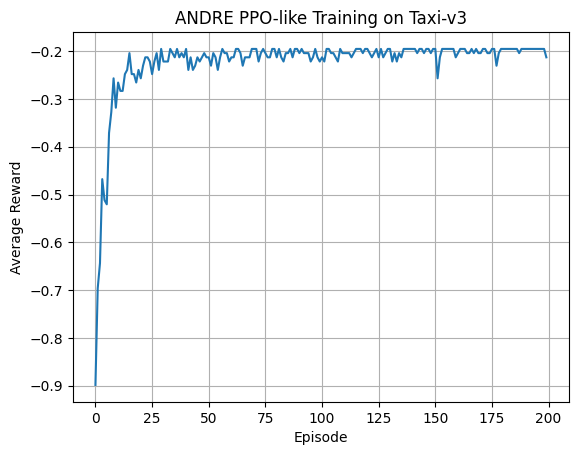

In [ ]:
import torch
import torch.nn as nn
import torch.optim as optim
import gym
import matplotlib.pyplot as plt

# === Hyperparameters ===
BETA = 10.0
NUM_ACTIONS = 6
INPUT_DIM = 10
GAMMA = 0.99
LAMBDA = 0.95
NUM_EPISODES = 200
LR = 0.001
STEPS_PER_BATCH = 1024
UPDATE_EPOCHS = 4
MINIBATCH_SIZE = 64
lambda_mse = 0.0
lambda_increment = 1e-2

# === CustomNeuron ===
class CustomNeuron(nn.Module):
    def __init__(self):
        super().__init__()
        self.raw_weights = nn.Parameter(torch.randn(3) * 0.1)

    def forward(self, x):
        weights = torch.softmax(self.raw_weights, dim=0)
        x1, x2, x3 = x, 1 - x, torch.ones_like(x)
        X1, X2, X3 = weights[0]*x1, weights[1]*x2, weights[2]*x3
        return X1 + X2 + X3 - (X1*X2 + X1*X3 + X2*X3) + (X1*X2*X3)

# === ANDRE === (Batched input support)
class ANDRE(nn.Module):
    def __init__(self, num_rules, input_dim):
        super().__init__()
        self.rules = nn.ModuleList([
            nn.ModuleList([CustomNeuron() for _ in range(input_dim)])
            for _ in range(num_rules)
        ])
        self.input_dim = input_dim

    def forward(self, x):  # x shape: (batch_size, input_dim)
        batch_size = x.shape[0]
        rule_outputs = []

        for rule in self.rules:
            conj = [neuron(x[:, i % self.input_dim].unsqueeze(1)) for i, neuron in enumerate(rule)]
            conj = torch.stack(conj)  # shape: (num_neurons, batch_size, 1)
            attn = torch.softmax(-BETA * conj.squeeze(-1), dim=0)
            rule_out = torch.sigmoid(5 * (torch.sum(attn * conj.squeeze(-1), dim=0)-0.5))
            rule_outputs.append(rule_out)

        rule_outputs = torch.stack(rule_outputs)  # (num_rules, batch_size)
        rule_attn = torch.softmax(BETA * rule_outputs, dim=0)
        return torch.sigmoid(5 * (torch.sum(rule_attn * rule_outputs, dim=0)-0.5))  # (batch_size,)

# === Value Network ===
class ValueNetwork(nn.Module):
    def __init__(self, state_dim=INPUT_DIM):
        super().__init__()
        # self.embed = nn.Embedding(500, 64)
        self.fc = nn.Sequential(
            nn.Linear(state_dim, 64),
            nn.ReLU(),
            nn.Linear(64, 1)
        )

    def forward(self, state):
        # x = self.embed(state)
        return self.fc(state).squeeze(-1)


# === GAE ===
def compute_gae(rewards, values, dones, gamma=0.99, lam=0.95):
    advantages, gae = [], 0
    values = values + [0]
    for t in reversed(range(len(rewards))):
        delta = rewards[t] + gamma * values[t+1] * (1 - dones[t]) - values[t]
        gae = delta + gamma * lam * (1 - dones[t]) * gae
        advantages.insert(0, gae)
    returns = [adv + v for adv, v in zip(advantages, values[:-1])]
    return advantages, returns

# === Init ===
env = gym.make("Taxi-v3")
andre_nets = nn.ModuleList([ANDRE(1, INPUT_DIM) for _ in range(NUM_ACTIONS)])
value_net = ValueNetwork(state_dim=INPUT_DIM)
optimizer = optim.Adam([p for net in andre_nets for p in net.parameters()] + list(value_net.parameters()), lr=LR)

# === Training ===
reward_log = []
avg_reward_log = []
obs = env.reset()
if isinstance(obs, tuple): obs = obs[0]
all_avg_rewards_andre = []

for ep in range(NUM_EPISODES):
    batch_obs, batch_acts, batch_log_probs, batch_vals, batch_rewards, batch_dones, batch_entropies = [], [], [], [], [], [], []
    ep_reward, step_count = 0, 0

    while step_count < STEPS_PER_BATCH:
        state = obs
        x = extract_high_level_features(state)
        # x[x == 0] = 0.1  # Avoid log(0) issues
        logits = torch.cat([andre(x) for andre in andre_nets], dim=0)
        # logits = logits / logits.sum(dim=0, keepdim=True)
        logits = 10 * (logits - logits.mean(dim=0, keepdim=True))  # Normalize logits
        # logits = torch.softmax(logits, dim=0)  # Normalize logits
        dist = torch.distributions.Categorical(logits=logits)
        action = dist.sample()

        log_prob = dist.log_prob(action)
        entropy = dist.entropy()
        # value = value_net(torch.tensor([state], dtype=torch.long))
        value = value_net(x)

        next_obs, reward, terminated, truncated, _ = env.step(action.item())
        done = terminated or truncated

        batch_obs.append(state)
        batch_acts.append(action.item())
        batch_log_probs.append(log_prob.item())
        batch_vals.append(value.item())
        batch_rewards.append(reward)
        batch_dones.append(done)
        batch_entropies.append(entropy.item())

        obs = next_obs if not isinstance(next_obs, tuple) else next_obs[0]
        ep_reward += reward
        step_count += 1

        if done:
            reward_log.append(ep_reward)
            obs = env.reset()
            if isinstance(obs, tuple): obs = obs[0]
            ep_reward = 0

    with torch.no_grad():
        last_val = value_net(extract_high_level_features(obs)).item()
        # last_val = value_net(torch.tensor([obs], dtype=torch.float32)).item()

    values = batch_vals + [last_val]
    advantages, returns = compute_gae(batch_rewards, values, batch_dones, GAMMA, LAMBDA)
    advantages = torch.tensor(advantages)
    returns = torch.tensor(returns)
    advantages = (advantages - advantages.mean()) / (advantages.std() + 1e-8)

    obs_tensor = torch.tensor(batch_obs, dtype=torch.long)
    act_tensor = torch.tensor(batch_acts, dtype=torch.long)
    logp_old = torch.tensor(batch_log_probs)
    entropies = torch.tensor(batch_entropies)

    for _ in range(UPDATE_EPOCHS):
        for i in range(0, STEPS_PER_BATCH, MINIBATCH_SIZE):
            idx = slice(i, i + MINIBATCH_SIZE)
            obs_list = obs_tensor[idx].tolist()
            x_batch = torch.cat([extract_high_level_features(s) for s in obs_list])
            logits = torch.stack([andre(x_batch) for andre in andre_nets], dim=1).squeeze(0)
            logits = 10 * (logits - logits.mean(dim=1, keepdim=True))  # Normalize logits
            # probs = torch.softmax(logits, dim=1)
            dist = torch.distributions.Categorical(logits=logits)
            logp = dist.log_prob(act_tensor[idx])
            ratio = torch.exp(logp - logp_old[idx])

            surr1 = ratio * advantages[idx]
            surr2 = torch.clamp(ratio, 0.8, 1.2) * advantages[idx]
            policy_loss = -torch.min(surr1, surr2).mean()

            val_pred = value_net(x_batch)
            # val_pred = value_net(obs_tensor[idx])
            value_loss = nn.functional.mse_loss(val_pred, returns[idx])

            entropy_bonus = entropies[idx].mean()

            # === Supervised MSE Loss on Action Targets ===
            # Create one-hot vectors for taken actions
            one_hot_targets = torch.nn.functional.one_hot(act_tensor[idx], num_classes=NUM_ACTIONS).float()
            # print(one_hot_targets)

            # Get logits (shape: [batch_size, NUM_ACTIONS])
            andre_outputs = torch.stack([andre(x_batch) for andre in andre_nets], dim=1).squeeze(0)

            # Normalize logits with softmax
            # andre_probs = torch.softmax(andre_outputs, dim=1)

            # MSE between predicted probabilities and one-hot action vectors
            mse_supervised = nn.functional.mse_loss(andre_outputs, one_hot_targets)
            lambda_mse += lambda_increment
            lambda_mse = min(lambda_mse, 0.5)  # Ensure lambda_mse is non-negative
            loss = policy_loss + 0.5 * value_loss - 0.001 * entropy_bonus + lambda_mse * mse_supervised

            optimizer.zero_grad()
            loss.backward()
            nn.utils.clip_grad_norm_([p for net in andre_nets for p in net.parameters()], 1.0)
            optimizer.step()

    avg_reward = reward_log[-1] / step_count if step_count > 0 else 0
    avg_reward_log.append(avg_reward)
    print(f"Episode {ep+1}/{NUM_EPISODES}, Avg Reward: {avg_reward:.2f}.")

plt.plot(avg_reward_log)
plt.title("PPO-ANDRE-Critic Training on Taxi-v3")
plt.xlabel("Episode")
plt.ylabel("Average Reward")
plt.grid(True)
plt.show()


In [49]:
def widen_weights(weight_list, eta=10):
    """
    Manipulate weights by applying a linear transformation.
    :param weight_list: List of weights to manipulate.
    :param eta: Scaling factor for the transformation.
    :return: Manipulated weights.
    """
    manipulated_weights = []
    for weights in weight_list:
        mean_weight = np.mean(weights)
        new_weights = [float(weight + eta * (weight - mean_weight)) for weight in weights]
        new_weights = [max(0, min(1, weight)) for weight in new_weights]  # Ensure weights are between 0 and 1
        # convert values between 0 and 1 to 0
        new_weights = [0 if weight < 1 else weight for weight in new_weights]
        manipulated_weights.append(new_weights)
    return manipulated_weights

In [50]:
andre_weights = []
for action_idx, andre_net in enumerate(andre_nets):
    rule_weights = []
    for rule in andre_net.rules:
        neuron_weights = []
        for neuron in rule:
            weights = torch.softmax(neuron.raw_weights, dim=0).detach().numpy().tolist()
            neuron_weights.append(weights)
        neuron_weights = widen_weights(neuron_weights, eta=10)  # Apply eta to weights
        rule_weights.append(neuron_weights)
    andre_weights.append(rule_weights)
andre_weights

[[[[1, 0, 0],
   [0, 0, 1],
   [0, 0, 1],
   [0, 0, 1],
   [1, 0, 0],
   [0, 0, 1],
   [0, 0, 1],
   [0, 0, 1],
   [0, 1, 0],
   [0, 0, 1]]],
 [[[0, 1, 1],
   [1, 0, 0],
   [0, 0, 1],
   [0, 0, 1],
   [0, 0, 1],
   [0, 0, 1],
   [0, 0, 1],
   [1, 0, 0],
   [0, 0, 1],
   [0, 1, 0]]],
 [[[0, 0, 1],
   [0, 0, 1],
   [0, 0, 1],
   [0, 0, 1],
   [0, 0, 1],
   [0, 0, 1],
   [0, 0, 1],
   [0, 0, 1],
   [0, 0, 1],
   [1, 0, 0]]],
 [[[0, 0, 0],
   [1, 0, 0],
   [1, 0, 0],
   [1, 0, 0],
   [0, 0, 1],
   [1, 0, 0],
   [0, 1, 0],
   [1, 0, 0],
   [1, 0, 0],
   [0, 0, 0]]],
 [[[0, 0, 1],
   [0, 0, 1],
   [0, 0, 1],
   [0, 0, 1],
   [1, 0, 0],
   [1, 0, 0],
   [1, 0, 0],
   [0, 0, 1],
   [0, 1, 0],
   [0, 0, 1]]],
 [[[0, 0, 1],
   [0, 0, 1],
   [0, 0, 1],
   [0, 0, 1],
   [0, 0, 1],
   [1, 0, 0],
   [0, 1, 0],
   [0, 1, 0],
   [0, 1, 0],
   [0, 1, 0]]]]

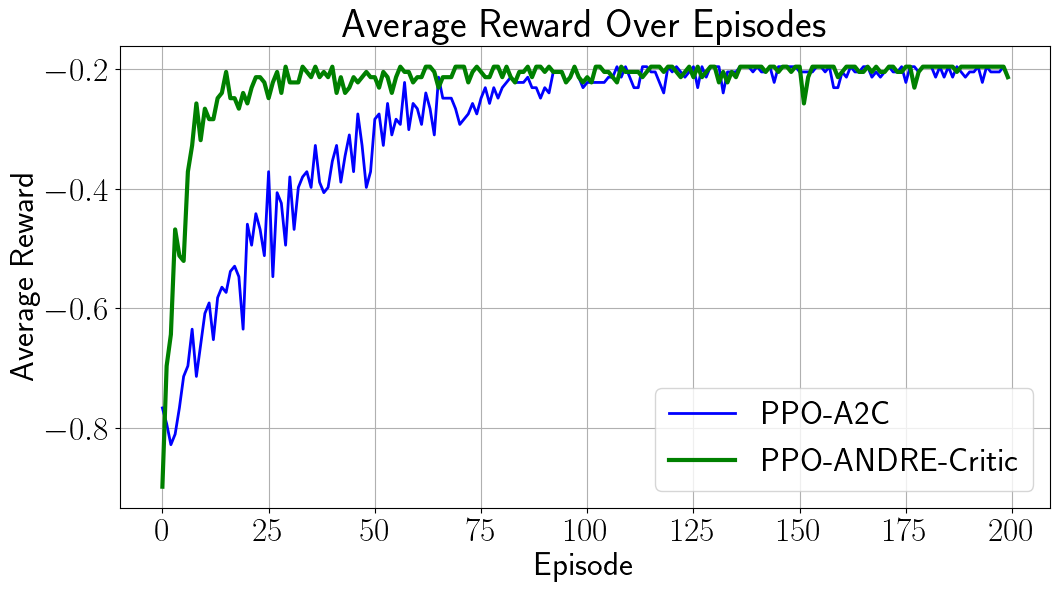

In [60]:
# plot loss functions for ppo and andre
plt.rcParams.update({'font.size': 24, 'text.usetex': True})  # Set global font size
plt.figure(figsize=(12, 6))
plt.plot(all_avg_rewards, label='PPO-A2C', color='blue', linewidth=2)
plt.plot(avg_reward_log, label='PPO-ANDRE-Critic', color='green', linewidth=3)
plt.title('Average Reward Over Episodes')
plt.xlabel('Episode')
plt.ylabel('Average Reward')
plt.grid()
plt.legend()
plt.show()

## Q-learning

Episode 1/2000, Total Reward: -3.67, Steps: 200.
Episode 2/2000, Total Reward: -3.49, Steps: 200.
Episode 3/2000, Total Reward: -3.49, Steps: 200.
Episode 4/2000, Total Reward: -3.85, Steps: 200.
Episode 5/2000, Total Reward: -4.62, Steps: 200.
Episode 6/2000, Total Reward: -3.58, Steps: 200.
Episode 7/2000, Total Reward: -3.27, Steps: 200.
Episode 8/2000, Total Reward: -4.13, Steps: 200.
Episode 9/2000, Total Reward: -3.45, Steps: 200.
Episode 10/2000, Total Reward: -3.94, Steps: 200.
Episode 11/2000, Total Reward: -4.31, Steps: 200.
Episode 12/2000, Total Reward: -3.76, Steps: 200.
Episode 13/2000, Total Reward: -3.65, Steps: 160.
Episode 14/2000, Total Reward: -3.72, Steps: 200.
Episode 15/2000, Total Reward: -3.94, Steps: 200.
Episode 16/2000, Total Reward: -4.08, Steps: 200.
Episode 17/2000, Total Reward: -3.63, Steps: 200.
Episode 18/2000, Total Reward: -4.04, Steps: 200.
Episode 19/2000, Total Reward: -4.17, Steps: 200.
Episode 20/2000, Total Reward: -4.13, Steps: 200.
Episode 2

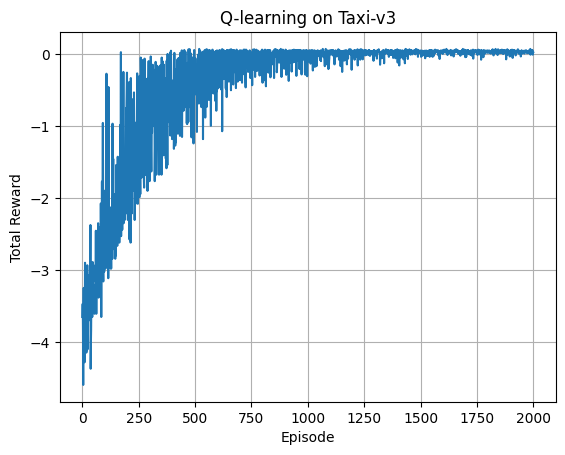

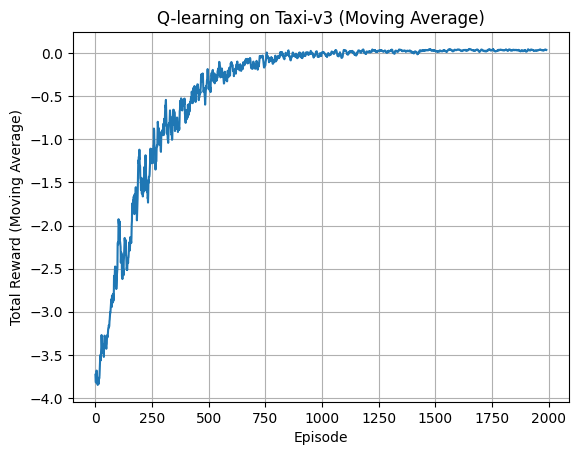

In [44]:
# from turtle import mode
import gym
import numpy as np
import matplotlib.pyplot as plt

# Create environment
env = gym.make("Taxi-v3")

# Initialize Q-table
state_space_size = env.observation_space.n  # 500
action_space_size = env.action_space.n      # 6
Q = np.zeros((state_space_size, action_space_size))

# Hyperparameters
alpha = 0.1      # Learning rate
gamma = 0.99     # Discount factor
epsilon = 1.0    # Exploration rate
epsilon_decay = 0.995
min_epsilon = 0.01
episodes = 2000
max_steps = 200  # per episode

reward_log = []
memory = []

# Training loop
for ep in range(episodes):
    state = env.reset()
    if isinstance(state, tuple):  # for newer gym versions
        state = state[0]

    total_reward = 0

    for step in range(max_steps):
        if np.random.rand() < epsilon:
            action = env.action_space.sample()
        else:
            action = np.argmax(Q[state])

        next_state, reward, done, truncated, _ = env.step(action)
        next_state = next_state if not isinstance(next_state, tuple) else next_state[0]

        best_next_action = np.argmax(Q[next_state])
        td_target = reward + gamma * Q[next_state][best_next_action]
        td_error = td_target - Q[state][action]
        Q[state][action] += alpha * td_error

        state = next_state
        total_reward += reward
        s = extract_high_level_features(state)
        s_ = extract_high_level_features(next_state)
        memory.append((state, s, action, reward, s_, done))

        if done or truncated:
            break

    reward_log.append(total_reward/max_steps)
    epsilon = max(min_epsilon, epsilon * epsilon_decay)
    print(f"Episode {ep+1}/{episodes}, Total Reward: {total_reward/step:.2f}, Steps: {step+1}.")

# Plot rewards
plt.plot(reward_log)
plt.title("Q-learning on Taxi-v3")
plt.xlabel("Episode")
plt.ylabel("Total Reward")
plt.grid(True)
plt.show()

# plot reward_log moving average
window_size = 10
moving_avg = np.convolve(reward_log, np.ones(window_size)/window_size, mode='valid')
plt.plot(moving_avg)
plt.title("Q-learning on Taxi-v3 (Moving Average)")
plt.xlabel("Episode")
plt.ylabel("Total Reward (Moving Average)")
plt.grid(True)
plt.show()


# Refine Memory

In [52]:
# === Remove duplicates from action_memory ===
from collections import defaultdict

deduped_action_memory = defaultdict(list)

for action, samples in action_memory.items():
    seen = set()
    for s, out in samples:
        # Convert s to a tuple of floats for hashing
        key = tuple(float(x) for x in s.flatten().tolist()), float(out.item())
        if key not in seen:
            seen.add(key)
            deduped_action_memory[action].append((s, out))

# Replace original with deduplicated version
action_memory = dict(deduped_action_memory)

# Show updated summary
summary = {f"action_{a}": len(samples) for a, samples in action_memory.items()}
summary


{'action_0': 54,
 'action_1': 53,
 'action_2': 67,
 'action_3': 63,
 'action_4': 79,
 'action_5': 75}

In [65]:
# === Organize memory by action ===
action_memory = {a: [] for a in range(6)}
for mem in memory:
    state = mem[0]
    s = mem[1]
    action = mem[2]
    reward = mem[3]
    s_ = mem[4]
    outputs = extract_desired_rule_outputs(state, reward)
    # print(f"State: {state}, Action: {action}, Outputs: {outputs}")
    action_memory[action].append((s, outputs[0][action]))

# Show summary of action_memory sizes
summary = {f"action_{a}": len(samples) for a, samples in action_memory.items()}
summary


{'action_0': 24070,
 'action_1': 24009,
 'action_2': 21768,
 'action_3': 22151,
 'action_4': 7392,
 'action_5': 7241}

In [36]:
import torch
import torch.nn as nn
import torch.optim as optim
from copy import deepcopy
import matplotlib.pyplot as plt
BETA = 20.0  # Example value for beta
LAMBDA = 10.0
# Define CustomNeuron and FuzzyDisjunctionNet
class CustomNeuron(nn.Module):
    def __init__(self):
        super(CustomNeuron, self).__init__()
        self.raw_weights = nn.Parameter(torch.randn(3) * 0.1)  # Small init to prevent saturation

    def forward(self, x):
        self.weights = torch.softmax(self.raw_weights, dim=0)
        x1 = x
        x2 = 1 - x
        x3 = torch.ones_like(x)
        X1 = self.weights[0] * x1
        X2 = self.weights[1] * x2
        X3 = self.weights[2] * x3
        activated_input = X1 + X2 + X3 - (X1 * X2 + X1 * X3 + X2 * X3) + (X1 * X2 * X3)
        return activated_input

class FuzzyDisjunctionNet(nn.Module):
    def __init__(self, num_rules, num_neurons_per_rule, input_dim):
        super(FuzzyDisjunctionNet, self).__init__()
        self.num_rules = num_rules
        self.num_neurons = num_neurons_per_rule
        self.input_dim = input_dim
        self.rules = nn.ModuleList([
            nn.ModuleList([CustomNeuron() for _ in range(num_neurons_per_rule)])
            for _ in range(num_rules)
        ])

    def forward(self, x):
        self.saved_weights = []
        self.entropies = []
        rule_outputs = []

        for rule in self.rules:
            conjunctions = []
            rule_weights = []
            entropy_sum = 0.0
            for i, neuron in enumerate(rule):
                xi = x[:, [i % self.input_dim]]
                conjunctions.append(neuron(xi))
                weights = neuron.weights
                rule_weights.append(weights)
                entropy_sum += -(weights * torch.log(weights + 1e-6)).sum()
            rule_vector = torch.cat(rule_weights)
            self.saved_weights.append(rule_vector)
            self.entropies.append(entropy_sum)
            # Soft min of neuron outputs using attention mechanism
            # find -beta * outputs for all neurons, where beta is a hyperparameter
            attention_weights = torch.softmax(-BETA * torch.stack(conjunctions), dim=0)
            outputs = [attention_weights[i] * conjunctions[i] for i in range(self.num_neurons)]
            activated_outputs = torch.sigmoid(LAMBDA*(sum(outputs) - 0.5))  # Apply sigmoid to the sum
            rule_outputs.append(activated_outputs)

        # Fuzzy disjunction: Soft max of rule outputs using attention mechanism
        # find BETA * rule_outputs for all rules, where beta is a hyperparameter
        attention_weights = torch.softmax(BETA * torch.stack(rule_outputs), dim=0)
        rule_outputs = [attention_weights[i] * rule_outputs[i] for i in range(self.num_rules)]
        activated_output = torch.sigmoid(LAMBDA*(sum(rule_outputs) - 0.5))  # Apply sigmoid to the sum

        return activated_output

In [67]:
import numpy as np

def interpret_neuron_weights_(pred_values, Weights):
    """
    Interpret the weights of neurons and return a list of 'b_{i}', 'not(b_{i})', or '1'.

    Args:
        pred_value: The predicted value to be used in interpretation. it is a scalar value between 0 and 1.
        weights (numpy.ndarray): A 2D numpy array where each row corresponds to the weights of a neuron.

    Returns:
        list: A list of strings ('b_{i}', 'not(b_{i})', or '1') for each neuron.
    """
    

    interpretations = []
    for i, weights in enumerate(Weights):

        # Find predicate value of a given neuron
        pred_value = pred_values[i]

        # compute {pred_value*weights[0], (1-pred_value)*weights[1], weights[2]}
        # new_weights = [pred_value * weights[0], (1 - pred_value) * weights[1], weights[2]]
        new_weights = weights

        max_index = np.argmax(new_weights)
        if max_index == 0:
            interpretations.append(f'b{i+1}')
            continue
        elif max_index == 1:
            interpretations.append(f'not(b{i+1})')
            continue
        else:
            interpretations.append('1')
    return interpretations

import numpy as np

In [71]:
X_train = [x for (x, y) in action_memory[5]]
y_train = [y for (x, y) in action_memory[5]]
X_train = torch.cat(X_train, dim=0).float()  # shape: (num_samples, feature_dim)
y_train = torch.stack(y_train).float().view(-1)  # shape: (num_samples,)

Restart 1/1 Final Loss: 0.0105


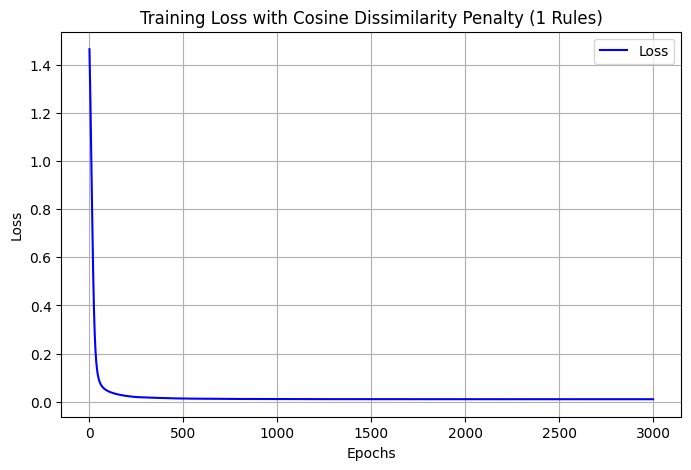


Final Weights of the Network:
Rule 1:
  Neuron 1: [0.1507444530725479, 0.6811161041259766, 0.16813942790031433]
  Neuron 2: [0.3636651039123535, 0.33740824460983276, 0.29892656207084656]
  Neuron 3: [0.22015368938446045, 0.5483678579330444, 0.23147843778133392]
  Neuron 4: [0.18003858625888824, 0.6324196457862854, 0.18754182755947113]
  Neuron 5: [0.8209528923034668, 0.09646638482809067, 0.08258073776960373]
  Neuron 6: [0.567842423915863, 0.20989686250686646, 0.2222607284784317]
  Neuron 7: [0.24497251212596893, 0.45861050486564636, 0.29641690850257874]
  Neuron 8: [0.19228801131248474, 0.610278308391571, 0.19743366539478302]
  Neuron 9: [0.6531918048858643, 0.173925518989563, 0.17288267612457275]
  Neuron 10: [0.8213307857513428, 0.09630582481622696, 0.08236333727836609]
  Neuron 11: [0.6423078179359436, 0.2042061984539032, 0.15348608791828156]
The most repeated rule is: 'h1 :- not(b1) and b2 and not(b3) and not(b4) and b5 and b6 and not(b7) and not(b8) and b9 and b10 and b11.'
Accu

In [72]:
from collections import Counter
# Parameters
num_rules = 1
num_neurons_per_rule = 11
input_dim = num_neurons_per_rule
num_samples = 1000
num_epochs = 3000
num_restarts = 1
similarity_weight = 0.1
entropy_weight = 0.01

# Cosine similarity function
cosine = nn.CosineSimilarity(dim=1)

# Multi-Restart Training
best_state_dict = None
best_loss = float('inf')
best_losses = []

for restart in range(num_restarts):
    model_nsre = FuzzyDisjunctionNet(num_rules, num_neurons_per_rule, input_dim)
    # criterion = nn.BCEWithLogitsLoss()
    criterion = nn.BCELoss()  # Use BCELoss for binary classification
    optimizer = optim.AdamW(model_nsre.parameters(), lr=0.01, weight_decay=1e-4)
    scheduler = optim.lr_scheduler.StepLR(optimizer, step_size=250, gamma=0.5)

    losses_nsre = []

    for epoch in range(num_epochs):
        optimizer.zero_grad()
        outputs = model_nsre(X_train).squeeze()
        bce_loss = criterion(outputs, y_train)

        # Cosine similarity loss
        penalty = 0.0
        for i in range(num_rules):
            for j in range(i + 1, num_rules):
                wi = model_nsre.saved_weights[i].view(num_neurons_per_rule, -1)
                wj = model_nsre.saved_weights[j].view(num_neurons_per_rule, -1)
                pairwise_sim = cosine(wi, wj).mean()
                penalty += pairwise_sim

        # Entropy regularization for exploration
        entropy_term = sum(model_nsre.entropies)

        total_loss = bce_loss #+ similarity_weight * penalty #+ entropy_weight * entropy_term
        total_loss.backward()
        nn.utils.clip_grad_norm_(model_nsre.parameters(), max_norm=1.0)
        optimizer.step()
        scheduler.step()
        losses_nsre.append(total_loss.item())

    final_loss = losses_nsre[-1]
    print(f"Restart {restart+1}/{num_restarts} Final Loss: {final_loss:.4f}")
    if final_loss < best_loss:
        best_loss = final_loss
        best_state_dict = deepcopy(model_nsre.state_dict())
        best_losses = losses_nsre

# Load the best model
best_model = FuzzyDisjunctionNet(num_rules, num_neurons_per_rule, input_dim)
best_model.load_state_dict(best_state_dict)

# Plot loss curve
plt.figure(figsize=(8, 5))
plt.plot(range(1, num_epochs + 1), losses_nsre, label="Loss", color="blue")
plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.title(f"Training Loss with Cosine Dissimilarity Penalty ({num_rules} Rules)")
plt.legend()
plt.grid(True)
plt.show()

# Save final weights for inspection
Weights_nsre = []
for rule in best_model.rules:
    rule_weights = []
    for neuron in rule:
        weights = torch.softmax(neuron.raw_weights, dim=0).detach().numpy().tolist()
        # rule_weights.append(np.round(weights, 0))
        rule_weights.append(weights)  # Store raw weights
    Weights_nsre.append(rule_weights)

print("\nFinal Weights of the Network:")
for rule_num, rule_weights in enumerate(Weights_nsre):
    print(f"Rule {rule_num+1}:")
    for i, weights in enumerate(rule_weights):
        print(f"  Neuron {i+1}: {weights}") 

# Rule interpretation
Predicate_values = X_train
input_dim = 4

Final_rules = []
for rule_num, weights in enumerate(Weights_nsre):
    Extracted_rules = []
    for i in range(len(Predicate_values)):
        pred_values = Predicate_values[i].numpy()
        preds = interpret_neuron_weights_(pred_values, weights)
        refined_preds = [pred for pred in preds if pred != '1']
        rule = f"h{rule_num+1} :- " + " and ".join(refined_preds) + "."
        Extracted_rules.append(rule)

    rule_counts = Counter(Extracted_rules)
    most_common_rule, count = rule_counts.most_common(1)[0]
    print(f"The most repeated rule is: '{most_common_rule}'")
    print(f"Accuracy over training data: {float(count/len(Extracted_rules))}.")

    Final_rules.append(most_common_rule)

# remove the "h{i+1} :- " part from each rule
Final_rules = [rule.replace(f"h{rule_num+1} :- ", "") for rule_num, rule in enumerate(Final_rules)]

# remove the "."
Final_rules = [rule.replace(".", "") for rule in Final_rules]

# convert the rules to a single rule
final_rule = "h :- " + " OR ".join(Final_rules) + "."
print("\n======================================")
print("Final Rule:")
print(final_rule)
print("======================================")


In [ ]:
import gym
import numpy as np
import torch
import pandas as pd

# === Memory Collection ===
memory = []

Q = np.zeros((env.observation_space.n, env.action_space.n))
alpha, gamma = 0.1, 0.99
epsilon, min_epsilon, epsilon_decay = 1.0, 0.01, 0.995

for ep in range(200):
    state = env.reset()
    if isinstance(state, tuple): state = state[0]

    for step in range(200):
        action = env.action_space.sample() if np.random.rand() < epsilon else np.argmax(Q[state])
        result = env.step(action)
        next_state, reward = result[:2]
        done = result[2] if len(result) == 4 else result[2] or result[3]
        if isinstance(next_state, tuple): next_state = next_state[0]

        best_next_action = np.argmax(Q[next_state])
        td_target = reward + gamma * Q[next_state][best_next_action]
        td_error = td_target - Q[state][action]
        Q[state][action] += alpha * td_error

        features = extract_high_level_features(state).squeeze(0).tolist()
        memory.append((features, action, reward))

        state = next_state
        if done:
            break
    epsilon = max(min_epsilon, epsilon * epsilon_decay)


In [23]:
import torch
import torch.nn as nn
import torch.optim as optim
import gym
import numpy as np
import matplotlib.pyplot as plt



# Dummy high-level feature extractor (replace this with your own logic)
# def extract_high_level_features(state):
#     features = torch.zeros(1, 10)
#     features[0, state % 10] = 1.0
#     return features

class CustomNeuron(nn.Module):
    def __init__(self):
        super().__init__()
        self.raw_weights = nn.Parameter(torch.randn(3) * 0.1)

    def forward(self, x):
        weights = torch.softmax(self.raw_weights, dim=0)
        x1, x2, x3 = x, 1 - x, torch.ones_like(x)
        X1, X2, X3 = weights[0]*x1, weights[1]*x2, weights[2]*x3
        return X1 + X2 + X3 - (X1*X2 + X1*X3 + X2*X3) + (X1*X2*X3)

class ANDRE(nn.Module):
    def __init__(self, num_rules, input_dim):
        super().__init__()
        self.rules = nn.ModuleList([
            nn.ModuleList([CustomNeuron() for _ in range(input_dim)])
            for _ in range(num_rules)
        ])
        self.input_dim = input_dim

    def forward(self, x):
        BETA = 20.0
        rule_outputs = []
        for rule in self.rules:
            conj = [neuron(x[:, i % self.input_dim].unsqueeze(1)) for i, neuron in enumerate(rule)]
            conj = torch.stack(conj)
            attn = torch.softmax(-BETA * conj.squeeze(-1), dim=0)
            rule_out = torch.sigmoid(5 * (torch.sum(attn * conj.squeeze(-1), dim=0)-0.5))
            rule_outputs.append(rule_out)
        rule_outputs = torch.stack(rule_outputs)
        rule_attn = torch.softmax(BETA * rule_outputs, dim=0)
        return torch.sigmoid(5 * (torch.sum(rule_attn * rule_outputs, dim=0)-0.5)).view(-1, 1)

# Initialize environment and networks
env = gym.make("Taxi-v3")
INPUT_DIM = 11
NUM_RULES = 1
NUM_ACTIONS = env.action_space.n
andre_q_nets = nn.ModuleList([ANDRE(NUM_RULES, INPUT_DIM) for _ in range(NUM_ACTIONS)])
optimizer = optim.Adam([p for net in andre_q_nets for p in net.parameters()], lr=0.1)
loss_fn = nn.MSELoss()

# Training hyperparameters
episodes = 500
gamma = 0.99
epsilon = 0.2
epsilon_decay = 0.995
min_epsilon = 0.01
max_steps = 100
reward_log = []

lambda_mse = 0.5
lambda_increment = 0.01

for ep in range(episodes):
    state = env.reset()
    if isinstance(state, tuple): state = state[0]
    total_reward = 0

    # To store for supervised loss
    states_list, actions_list, rewards_list = [], [], []

    for step in range(max_steps):
        x = extract_high_level_features(state)
        q_values = torch.cat([net(x) for net in andre_q_nets], dim=1)

        action = env.action_space.sample() if np.random.rand() < epsilon else torch.argmax(q_values).item()

        result = env.step(action)
        next_state, reward = result[:2]
        done = result[2] if len(result) == 4 else result[2] or result[3]
        if isinstance(next_state, tuple): next_state = next_state[0]

        x_next = extract_high_level_features(next_state)
        with torch.no_grad():
            q_next = torch.cat([net(x_next) for net in andre_q_nets], dim=1)
            target = reward + (0 if done else gamma * torch.max(q_next).item())

        q_value = andre_q_nets[action](x)
        td_loss = loss_fn(q_value, torch.tensor([[target]], dtype=torch.float32))


        # === Compute Supervised Loss ===
        desired_outputs = extract_desired_rule_outputs(state, reward)  # shape: (1, 6)
        andre_outputs = q_values

        mse_supervised = nn.functional.mse_loss(andre_outputs, desired_outputs)

        # === Combine Loss ===
        lambda_mse += lambda_increment
        lambda_mse = min(lambda_mse, 1.0)
        loss = td_loss #+ lambda_mse * mse_supervised

        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

        state = next_state
        total_reward += reward
        if done:
            break

    epsilon = max(min_epsilon, epsilon * epsilon_decay)
    reward_log.append(total_reward)
    print(f"Episode {ep+1}: Avg Reward = {total_reward/step:.2f}, Steps = {step+1}, Epsilon = {epsilon:.2f}")

# Plot learning curve
plt.plot(reward_log)
plt.title("ANDRE Q-learning on Taxi-v3")
plt.xlabel("Episode")
plt.ylabel("Total Reward")
plt.grid(True)
plt.show()


Episode 1: Avg Reward = -3.92, Steps = 100, Epsilon = 0.20
Episode 2: Avg Reward = -4.10, Steps = 100, Epsilon = 0.20
Episode 3: Avg Reward = -4.10, Steps = 100, Epsilon = 0.20
Episode 4: Avg Reward = -3.92, Steps = 100, Epsilon = 0.20
Episode 5: Avg Reward = -4.01, Steps = 100, Epsilon = 0.20
Episode 6: Avg Reward = -4.10, Steps = 100, Epsilon = 0.19
Episode 7: Avg Reward = -5.46, Steps = 100, Epsilon = 0.19
Episode 8: Avg Reward = -4.19, Steps = 100, Epsilon = 0.19
Episode 9: Avg Reward = -1.83, Steps = 100, Epsilon = 0.19
Episode 10: Avg Reward = -4.01, Steps = 100, Epsilon = 0.19
Episode 11: Avg Reward = -5.56, Steps = 100, Epsilon = 0.19
Episode 12: Avg Reward = -5.28, Steps = 100, Epsilon = 0.19
Episode 13: Avg Reward = -4.28, Steps = 100, Epsilon = 0.19
Episode 14: Avg Reward = -2.37, Steps = 100, Epsilon = 0.19
Episode 15: Avg Reward = -5.74, Steps = 100, Epsilon = 0.19
Episode 16: Avg Reward = -3.19, Steps = 100, Epsilon = 0.18
Episode 17: Avg Reward = -4.37, Steps = 100, Epsi

KeyboardInterrupt: 

Episode 1: Avg Reward = -3.28, Steps = 100, Epsilon = 0.50
Episode 2: Avg Reward = -2.65, Steps = 100, Epsilon = 0.50
Episode 3: Avg Reward = -2.46, Steps = 100, Epsilon = 0.49
Episode 4: Avg Reward = -2.28, Steps = 100, Epsilon = 0.49
Episode 5: Avg Reward = -2.37, Steps = 100, Epsilon = 0.49
Episode 6: Avg Reward = -3.10, Steps = 100, Epsilon = 0.49
Episode 7: Avg Reward = -3.10, Steps = 100, Epsilon = 0.48
Episode 8: Avg Reward = -2.19, Steps = 100, Epsilon = 0.48
Episode 9: Avg Reward = -3.10, Steps = 100, Epsilon = 0.48
Episode 10: Avg Reward = -2.65, Steps = 100, Epsilon = 0.48
Episode 11: Avg Reward = -2.37, Steps = 100, Epsilon = 0.47
Episode 12: Avg Reward = -2.65, Steps = 100, Epsilon = 0.47
Episode 13: Avg Reward = -1.83, Steps = 100, Epsilon = 0.47
Episode 14: Avg Reward = -2.28, Steps = 100, Epsilon = 0.47
Episode 15: Avg Reward = -2.37, Steps = 100, Epsilon = 0.46
Episode 16: Avg Reward = -2.19, Steps = 100, Epsilon = 0.46
Episode 17: Avg Reward = -2.65, Steps = 100, Epsi

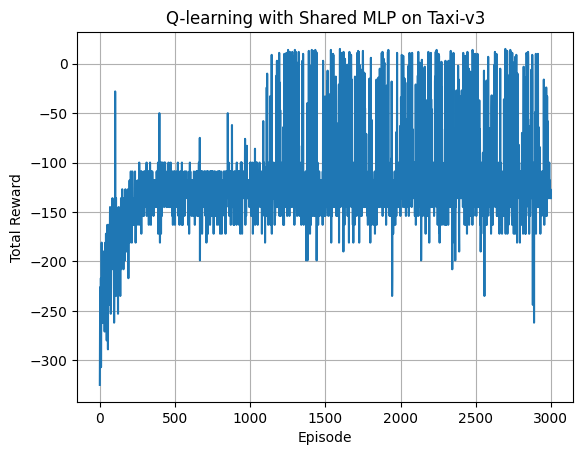

In [30]:
import torch
import torch.nn as nn
import torch.optim as optim
import gym
import numpy as np
import matplotlib.pyplot as plt

# === Dummy high-level feature extractor ===
# def extract_high_level_features(state):
#     features = torch.zeros(11)
#     features[state % 11] = 1.0
#     return features.unsqueeze(0)  # shape: (1, INPUT_DIM)

# === Multi-output MLP for Q-learning ===
class QNetwork(nn.Module):
    def __init__(self, input_dim, output_dim):
        super().__init__()
        self.model = nn.Sequential(
            nn.Linear(input_dim, 32),
            nn.ReLU(),
            nn.Linear(32, output_dim)
        )

    def forward(self, x):
        return self.model(x)  # returns Q-values for all actions

# === Environment and network initialization ===
env = gym.make("Taxi-v3")
INPUT_DIM = 11
NUM_ACTIONS = env.action_space.n
q_net = QNetwork(INPUT_DIM, NUM_ACTIONS)
optimizer = optim.Adam(q_net.parameters(), lr=0.01)
loss_fn = nn.MSELoss()

# === Training hyperparameters ===
episodes = 3000
gamma = 0.99
epsilon = 0.5
epsilon_decay = 0.995
min_epsilon = 0.1
max_steps = 100
reward_log = []

for ep in range(episodes):
    state = env.reset()
    if isinstance(state, tuple): state = state[0]
    total_reward = 0

    for step in range(max_steps):
        x = extract_high_level_features(state)
        q_values = q_net(x)

        if np.random.rand() < epsilon:
            action = env.action_space.sample()
        else:
            action = torch.argmax(q_values).item()

        result = env.step(action)
        next_state, reward = result[:2]
        done = result[2] if len(result) == 4 else result[2] or result[3]
        if isinstance(next_state, tuple): next_state = next_state[0]

        with torch.no_grad():
            next_x = extract_high_level_features(next_state)
            q_next = q_net(next_x)
            target = reward + (0 if done else gamma * torch.max(q_next).item())

        target_q_values = q_values.clone()
        target_q_values[0, action] = target

        loss = loss_fn(q_values, target_q_values)

        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

        state = next_state
        total_reward += reward
        if done:
            break

    epsilon = max(min_epsilon, epsilon * epsilon_decay)
    reward_log.append(total_reward)
    print(f"Episode {ep+1}: Avg Reward = {total_reward/step:.2f}, Steps = {step+1}, Epsilon = {epsilon:.2f}")

# === Plotting ===
plt.plot(reward_log)
plt.title("Q-learning with Shared MLP on Taxi-v3")
plt.xlabel("Episode")
plt.ylabel("Total Reward")
plt.grid(True)
plt.show()
